## Project 
139 data set

In [2]:
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import statsmodels.api as sm
import statsmodels.stats.api as sms
import scipy.stats as stats
from sklearn import preprocessing
from IPython.display import display
sns.set_theme(style="whitegrid")

In [ ]:
filename_1 = "data/gateways.csv"
filename_2 = "data/readings.csv"
filename_3 = "data/units.csv"

In [55]:
data_1 = pd.read_csv(filename_1, 
                   sep=';', index_col=13)
data_1.head(20)
#data_1.iloc[1999:2020] # id_unit from 2000 to end are NaN

,seen_last,install_date,Lon,idDepot,macAddress,versionFirmware,signal_dbm,lat,Vendor,hardware_model,id_unit,Technician,ipv4
gateway_id,,,,,,,,,,,,,
GW-00000,2024-04-08,"10/03/2023, 00:00:00",-8.89921,112,e2:f9:05:83:4d:20,v2.7.0,-66.2,38.91850,Fritsch,GWX-200,1831.0,Elenore Herrmann,67.49.73.170
GW-00001,"11/07/2024, 00:00:00","07/11/2016, 00:00:00",-7.87246,88,6d:a5:2b:72:5b:10,v1.2.5,-75.7,39.79636,Nogueira,GWX-100,488.0,Bradley Fleming,16.98.36.57
GW-00002,"10/02/2024, 00:00:00","05/04/2016, 00:00:00",-8.66738,85,ac:73:9a:fb:a3:73,v1.2.5,-71.4,38.82073,Leite,NODE-7,231.0,Sofia Loureiro,80.107.147.21
GW-00003,2025-01-24,2018-08-29,-6.64779,116,0f:21:99:19:d3:cb,v1.2.5,-76.6,41.01462,Speer,GWX-100,396.0,Michael Navarro,216.20.189.94
GW-00004,03 Aug 2024,2024/03/14,-8.80419,26,a7:13:08:aa:79:70,v2.7.0,-59.8,38.86962,Paiva Leite Lda.,NODE-9,1502.0,Ivan Branco,248.247.103.90
GW-00005,"10/20/2024, 00:00:00",2020-12-05,-8.31845,63,f9:c5:95:48:1e:bd,v2.7.0,-81.4,41.40283,Pacheco,NODE-7,1891.0,Lisa Burns,142.92.8.43
GW-00006,2024-08-10,"09/30/2023, 00:00:00",-9.11759,57,1e:d2:90:d0:ab:51,v3.4.1,-73.5,39.66395,Paiva Leite Lda.,NODE-9,963.0,Michael Cook,158.92.33.60
GW-00007,2024/04/24,2023-11-12,-9.10634,18,68:01:b8:49:d6:fa,v3.4.1,-74.1,40.13607,Melo,GWX-300,22.0,Etta Zahn-Briemer,100.140.32.72
GW-00008,"12/25/2024, 00:00:00","12/01/2016, 00:00:00",-7.62037,56,7e:36:3b:b5:94:21,v2.7.0,-63.1,39.32954,Pinheiro,GWX-300,1288.0,Anneli Kambs,14.255.71.253


gateway_id - Textual

seen_last - Time-series

install_date - Time-series

lon - Numerical(continuous)

idDeport - Discrete

macAddress - Textual

versionFirmware - Categorical

signal_dbm - Numerical(continuous)

lat - Numerical(continuous)

Vendor - Categorical

hardware_model - Categorical

id_unit - Numerical(continuous)

Technician - Categorical(nominal)

ipv4 - Textual

In [56]:
data_2 = pd.read_csv(filename_2, 
                    sep='\t')
data_2.head(20)

,id_unit,cycle_ts,currentMotor,dp_filter,oilTemperature,pressure_reservoir,rmsVibration,Flowmeter,dischargeDewpoint,Failure
0,U00078,24 Sep 2023,2.91072,17.08727,63.17362,10.42780,5.53225,24.90723,5.49963,0
1,U01922,2023-10-05,5.20071,14.68177,36.67755,8.84326,6.40699,26.62476,7.60072,1
2,U00548,2023-10-18,5.56161,44.22325,43.50675,8.03135,4.30464,26.39225,5.25673,0
3,U01551,21 Mar 2023,5.12227,21.50330,63.91073,7.86316,1.66650,22.98348,5.09449,1
4,U00298,04 Oct 2023,5.11036,29.84890,64.71004,9.78952,2.82960,33.75524,11.50507,0
5,U01522,12 Dec 2023,2.47593,NaN,63.34515,8.66470,5.10853,27.65622,5.79981,1
6,U00748,2023/04/23,6.60443,18.84023,40.67046,8.61937,NaN,25.53233,3.43388,1
7,U00565,2023/03/24,6.48482,26.42038,52.23038,8.45314,1.85331,26.09878,7.24156,0
8,U00588,"01/02/2023, 14:07:00",6.63109,NaN,60.44142,9.34893,3.28290,28.68901,16.55528,1
9,U01188,2023-03-17,4.51353,45.42224,57.41512,8.61459,2.45468,33.13947,8.77440,1


id_unit - Categorical(nominal)

cycle_ts - Time-series

currentMotor - Numerical(continuous)

dp_filter - Numerical(continuous)

oilTemperature - Numerical(continuous)

presure_reservoir - Numerical(continuous)

rmsVibration - Numerical(continuous)

Flowmeter - Numerical(continuous)
 
dischargeDewpoint - Numerical(continuous)

Failure - Categorical(Boolean)

In [57]:
data_3 = pd.read_csv(filename_3, 
                    sep=',',index_col=5
                    )
data_3.head(20)

,idDepot,duty_class,year_commission,serviceHours,overhaul_last,serial_number
id_unit,,,,,,
1,97,light,2022,7263.7,"09/23/2021, 00:00:00",GQ-0521-56531
2,81,heavy,2023,6053.4,2020-05-07,HN-5203-27688
3,56,light,2023,4921.4,2021/06/04,QC-5243-50182
4,53,3,2018,21803.6,25 Apr 2021,TC-5483-81500
5,54,normal,2020,15730.5,"08/13/2024, 00:00:00",XO-0640-55128
6,49,normal,2024,2672.6,07 Apr 2023,NL-5523-44373
7,54,normal,2017,26298.5,2021-12-02,GM-2661-34290
8,5,light,2019,17581.9,2015/05/15,DE-2078-95757
9,25,L,2022,9111.4,15 Jun 2018,MC-2132-88338


id_unit - Numerical

idDeport - Numerical

duty_class - Categorical 

year_commision - Numerical

service_hours - Numerical(Continuous)

overhaul_last - Time-series

serial_number - Textual

In [58]:
data_1.info()

<class 'pandas.core.frame.DataFrame'>
Index: 16000 entries, GW-00000 to GW-15999
Data columns (total 13 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   seen_last        16000 non-null  object 
 1   install_date     16000 non-null  object 
 2   Lon              16000 non-null  float64
 3   idDepot          16000 non-null  int64  
 4   macAddress       16000 non-null  object 
 5   versionFirmware  16000 non-null  object 
 6   signal_dbm       16000 non-null  float64
 7   lat              16000 non-null  float64
 8   Vendor           16000 non-null  object 
 9   hardware_model   16000 non-null  object 
 10  id_unit          2000 non-null   float64
 11  Technician       16000 non-null  object 
 12  ipv4             16000 non-null  object 
dtypes: float64(4), int64(1), object(8)
memory usage: 1.7+ MB


`id_unit` od 2000 az po koniec tabuľky su NaN 

In [59]:
data_2.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14052 entries, 0 to 14051
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   id_unit             14052 non-null  object 
 1   cycle_ts            14052 non-null  object 
 2   currentMotor        14052 non-null  float64
 3   dp_filter           13503 non-null  float64
 4   oilTemperature      14052 non-null  float64
 5   pressure_reservoir  14052 non-null  float64
 6   rmsVibration        13534 non-null  float64
 7   Flowmeter           14052 non-null  float64
 8   dischargeDewpoint   14052 non-null  float64
 9   Failure             14052 non-null  int64  
dtypes: float64(7), int64(1), object(2)
memory usage: 1.1+ MB


`dp_filter` a `rmsVibration` má NaN hodnoty

In [60]:
data_3.info()

<class 'pandas.core.frame.DataFrame'>
Index: 2000 entries, 1 to 2000
Data columns (total 6 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   idDepot          2000 non-null   int64  
 1   duty_class       2000 non-null   object 
 2   year_commission  2000 non-null   int64  
 3   serviceHours     1900 non-null   float64
 4   overhaul_last    2000 non-null   object 
 5   serial_number    2000 non-null   object 
dtypes: float64(1), int64(2), object(3)
memory usage: 109.4+ KB


`serviceHours` - NaN hodnoty

In [61]:
data_1.describe(include='all')

,seen_last,install_date,Lon,idDepot,macAddress,versionFirmware,signal_dbm,lat,Vendor,hardware_model,id_unit,Technician,ipv4
count,16000,16000,16000.000000,16000.000000,16000,16000,16000.000000,16000.000000,16000,16000,2000.000000,16000,16000
unique,1600,9723,NaN,NaN,16000,3,NaN,NaN,38,5,NaN,120,16000
top,2024-08-05,2023-05-31,NaN,NaN,e2:f9:05:83:4d:20,v1.2.5,NaN,NaN,Speer,NODE-9,NaN,Miguel Marques,67.49.73.170
freq,22,7,NaN,NaN,1,5359,NaN,NaN,810,3263,NaN,165,1
mean,NaN,NaN,-7.751588,58.854125,NaN,NaN,-70.170300,40.155156,NaN,NaN,1000.500000,NaN,NaN
std,NaN,NaN,0.891284,34.567290,NaN,NaN,10.006577,0.900882,NaN,NaN,577.494589,NaN,NaN
min,NaN,NaN,-9.299980,0.000000,NaN,NaN,-107.300000,38.600070,NaN,NaN,1.000000,NaN,NaN
25%,NaN,NaN,-8.524577,29.000000,NaN,NaN,-77.000000,39.373440,NaN,NaN,500.750000,NaN,NaN
50%,NaN,NaN,-7.758115,59.000000,NaN,NaN,-70.200000,40.163690,NaN,NaN,1000.500000,NaN,NaN
75%,NaN,NaN,-6.980605,89.000000,NaN,NaN,-63.400000,40.937605,NaN,NaN,1500.250000,NaN,NaN


In [62]:
data_2.describe(include='all')

,id_unit,cycle_ts,currentMotor,dp_filter,oilTemperature,pressure_reservoir,rmsVibration,Flowmeter,dischargeDewpoint,Failure
count,14052,14052,14052.000000,13503.000000,14052.000000,14052.000000,13534.000000,14052.000000,14052.000000,14052.000000
unique,2112,4579,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
top,U01347,13 Dec 2023,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freq,17,21,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mean,NaN,NaN,5.277158,24.073502,50.628361,8.698509,3.083622,27.925684,7.971619,0.118844
std,NaN,NaN,2.893927,11.434870,68.623763,0.601964,1.643651,4.007567,3.507052,0.323617
min,NaN,NaN,0.115880,7.081150,-999.000000,6.500000,0.500000,15.000000,-5.117820,0.000000
25%,NaN,NaN,3.731485,16.246110,46.753862,8.298048,1.936292,25.222520,5.666065,0.000000
50%,NaN,NaN,5.127835,21.249320,55.072740,8.696900,2.718050,27.936505,7.972520,0.000000
75%,NaN,NaN,6.643298,28.690820,63.030540,9.102232,3.830090,30.630375,10.308608,0.000000


In [63]:
data_3.describe(include='all')

,idDepot,duty_class,year_commission,serviceHours,overhaul_last,serial_number
count,2000.000000,2000,2000.000000,1900.000000,2000,2000
unique,NaN,20,NaN,NaN,1842,2000
top,NaN,L,NaN,NaN,"12/10/2021, 00:00:00",GQ-0521-56531
freq,NaN,252,NaN,NaN,3,1
mean,54.737500,NaN,2020.343000,14588.644842,NaN,NaN
std,34.325074,NaN,2.547076,8953.209427,NaN,NaN
min,0.000000,NaN,2012.000000,1303.000000,NaN,NaN
25%,24.000000,NaN,2019.000000,8224.525000,NaN,NaN
50%,53.000000,NaN,2021.000000,12343.300000,NaN,NaN
75%,83.000000,NaN,2022.000000,18475.050000,NaN,NaN


## Short report: 
Údaje sú rozdelené do 3 súborov vo formáte .csv (**gateway**, **readings**, **units**). V súbore **gateway** sa na oddelenie údajov používa znak „;“ a ako index slúži **gateway_id**. V súbore **readings** sa na oddelenie údajov používa znak „\t“. Súbor **units** vyžaduje na oddelenie údajov znak „,“ a ako index sa používa **id_unit**. Súbory **readings** a **units** sú prepojené, pretože súbor **readings** obsahuje informácie o kontrole jednotky. Nie som si istý, ale súbor **gateway** obsahuje informácie o zariadení, ktoré sa používa na kontrolu alebo inštaláciu niečoho na jednotke. Počet záznamov: **gateway** – 16 000; **readings** – 14 052; **units** – 2 000. **gateway** má 13 atribútov (float64(4), int64(1), str(8)); **readings** má 10 atribútov (float64(7), int64(1), str(2)); **unitsy** má 6 atribútov (float64(1), int64(2), str(3)).

## Important attributes:
**units**: duty_class; service_hours

**readings**: currentMotor; dp_filter; oilTemperature; pressure_reservoir; rmsVibration; Flowmeter; dischargeDewpoint; Failure

**gateways**: Lon; signal_dbm; hardware_model; lat; versionFirmware; Vendor

In [64]:
data_3.dropna().shape[0]

1900

In [65]:
data_3.isnull().sum()

idDepot              0
duty_class           0
year_commission      0
serviceHours       100
overhaul_last        0
serial_number        0
dtype: int64

In [66]:
data_3[data_3.isnull().any(axis=1)]

,idDepot,duty_class,year_commission,serviceHours,overhaul_last,serial_number
id_unit,,,,,,
66,86,light,2020,NaN,19 Apr 2021,WJ-1589-63660
76,1,2,2022,NaN,"09/30/2020, 00:00:00",BQ-8095-74652
130,84,heavy,2020,NaN,2017-02-15,RL-2537-51896
153,24,L,2021,NaN,28 May 2021,YW-4417-33641
162,74,2,2021,NaN,16 Oct 2016,LN-7120-15596
...,...,...,...,...,...,...
1932,8,L,2020,NaN,"11/09/2020, 00:00:00",EF-9953-30481
1968,44,1,2022,NaN,"03/04/2016, 00:00:00",CA-8817-92790
1994,16,1,2021,NaN,05 Aug 2024,PS-9327-19274


In [67]:
data_3.duty_class.unique()

array(['light', 'heavy', ' 3 ', 'normal', 'L', ' 1 ', 'med', '2', 'N',
       '1', ' heavy ', '3', ' med ', ' L ', ' light ', 'H', ' H ',
       ' normal ', ' N ', ' 2 '], dtype=object)

In [68]:
data_3['duty_class'] = (
    data_3['duty_class']
    .str.strip()
    .replace({
        '1': 'light',
        'L': 'light',
        'light': 'light',

        '2': 'medium',
        'med': 'medium',
        'N': 'medium',
        'normal': 'medium',

        '3': 'heavy',
        'H': 'heavy',
        'heavy': 'heavy'
    })
)

In [69]:
data_3.duty_class.unique()

array(['light', 'heavy', 'medium'], dtype=object)

In [70]:
data_3.groupby('duty_class').size()

duty_class
heavy     510
light     804
medium    686
dtype: int64

In [71]:
data_3.serviceHours.describe()

count     1900.000000
mean     14588.644842
std       8953.209427
min       1303.000000
25%       8224.525000
50%      12343.300000
75%      18475.050000
max      45000.000000
Name: serviceHours, dtype: float64

<Axes: xlabel='serviceHours', ylabel='duty_class'>

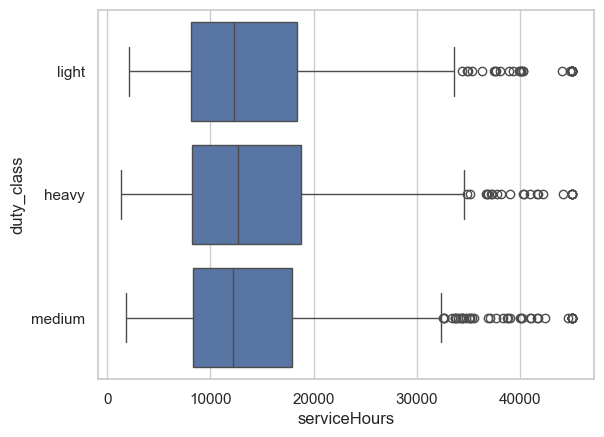

In [72]:
sns.boxplot(data=data_3, x="serviceHours", y="duty_class")

array([[<Axes: title={'center': 'idDepot'}>,
        <Axes: title={'center': 'year_commission'}>],
       [<Axes: title={'center': 'serviceHours'}>, <Axes: >]], dtype=object)

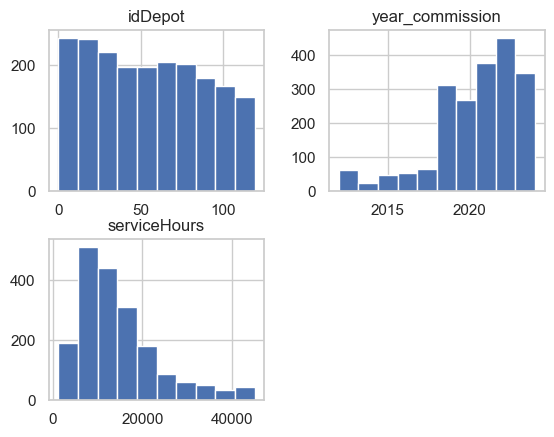

In [73]:
data_3.hist()

Analyza jednotlivych atributov

**Vyber atributov:** Atributy sme vyberali predovsetkym podla toho, ako suvisia s ulohou predikcie `Failure`. Zahrnuli sme vsetkych 7 senzorov z `readings`, ktore opisuju stav stroja, a z `units` atributy `serviceHours`, `duty_class` a `year_commission`, ktore vyjadruju opotrebenie a zataz jednotky. Pri vybere sme chceli mat zastupene ciselne aj kategoricke atributy a viac tabuliek. Identifikatory a casove atributy sme do tejto casti nezaradili, pretoze ich analyzujeme inak. Vyber je zatial prvotny a v dalsich fazach ho mozeme spresnit.

In [74]:
sensor_cols = ['currentMotor', 'dp_filter', 'oilTemperature', 'pressure_reservoir',
               'rmsVibration', 'Flowmeter', 'dischargeDewpoint']
# ciselne atributy su 7 senzorov + serviceHours (units) + signal_dbm (gateways)
attrs = [(data_2, c) for c in sensor_cols] + [(data_3, 'serviceHours'), (data_1, 'signal_dbm')]
# 10. atribut je kategoria duty_class (units), ta ide zvlast

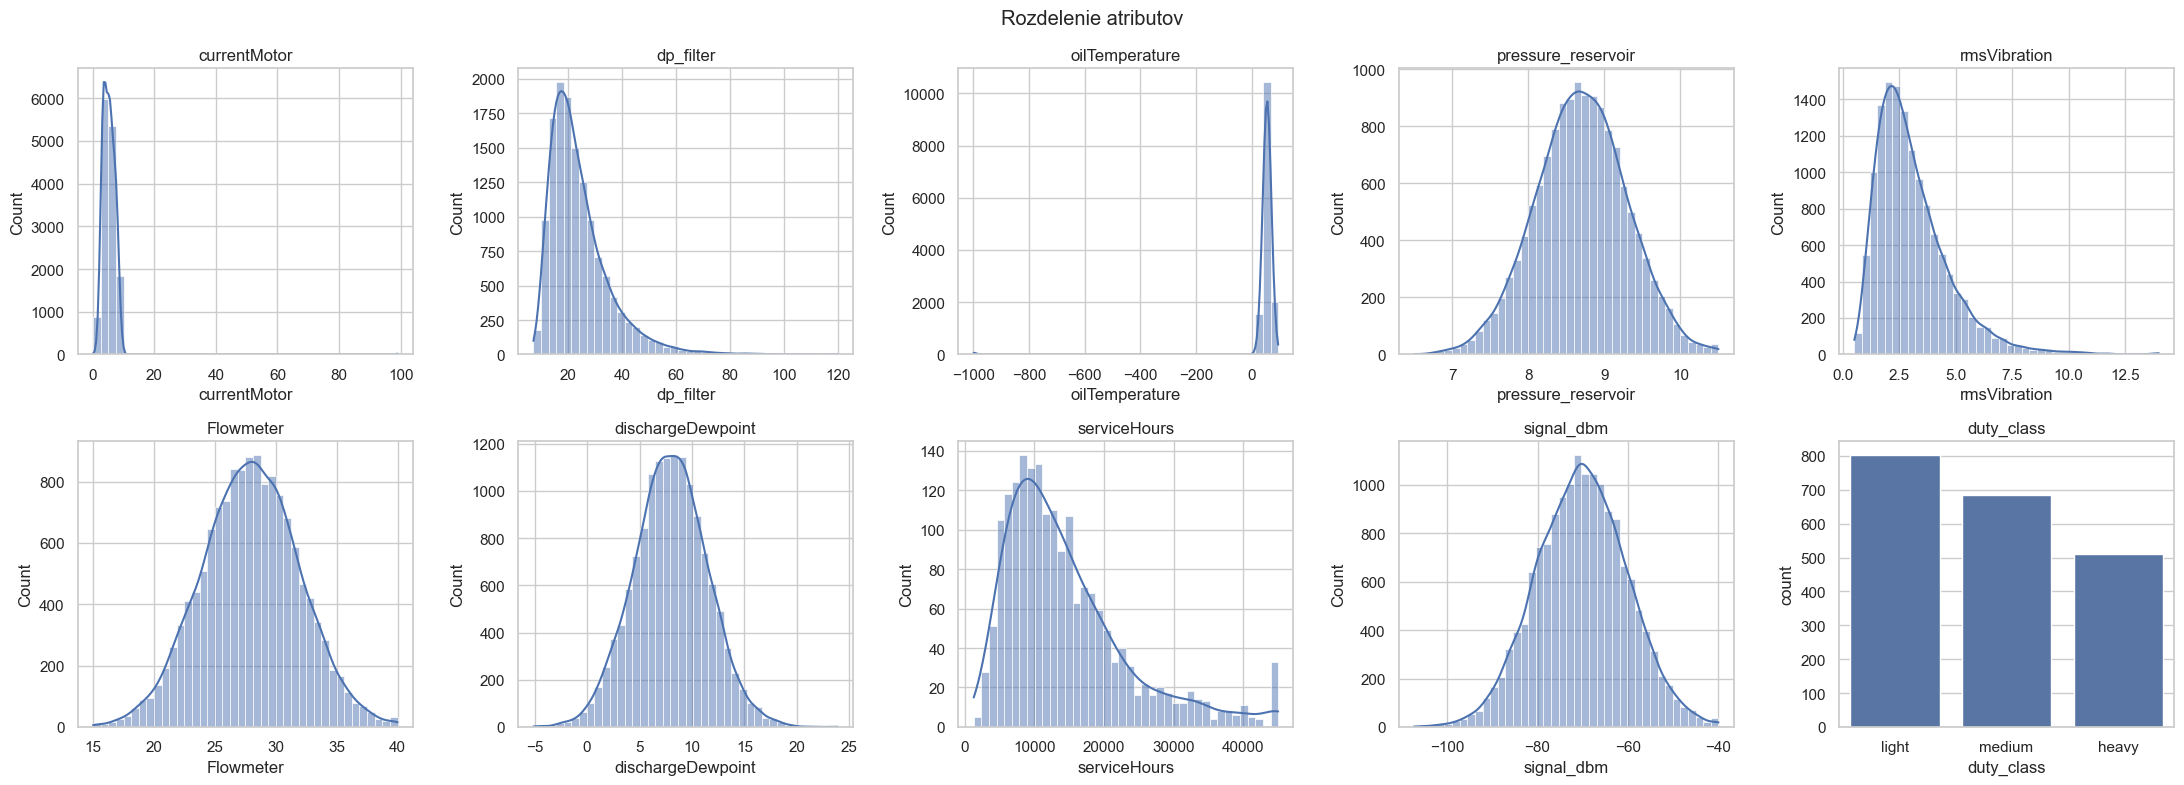

In [75]:
fig, axes = plt.subplots(2, 5, figsize=(22, 8))
axes = axes.ravel()

for ax, (df_, c) in zip(axes, attrs):
    sns.histplot(df_[c].dropna(), bins=40, kde=True, ax=ax)
    ax.set_title(c)
    
sns.countplot(x='duty_class', data=data_3, order=['light', 'medium', 'heavy'], ax=axes[9])
axes[9].set_title('duty_class')
plt.suptitle('Rozdelenie atributov')
plt.tight_layout(); plt.show()

- currentMotor a oilTemperature maju hlavnu cast hodnot blizko pri sebe, ale osi su natiahnute kvoli osamotenym extremom (99 pri motore, -999 pri oleji), preto graf vyzera ako jediny stlpec,   asi sa jedna o chybne kody
- serviceHours ma stlpec pri 45 000, co vyzera ako strop (hodnoty su orezane na maximum).
- dp_filter, rmsVibration a serviceHours su pravostranne sikme (vacsina hodnot je nizko, dlhy chvost je doprava).
- pressure_reservoir, Flowmeter, dischargeDewpoint a signal_dbm maju zvonovity tvar, su priblizne normalne.
- duty_class nie je uplne vyvazena (light 804, medium 686, heavy 510), ale kazda trieda ma dost zaznamov.

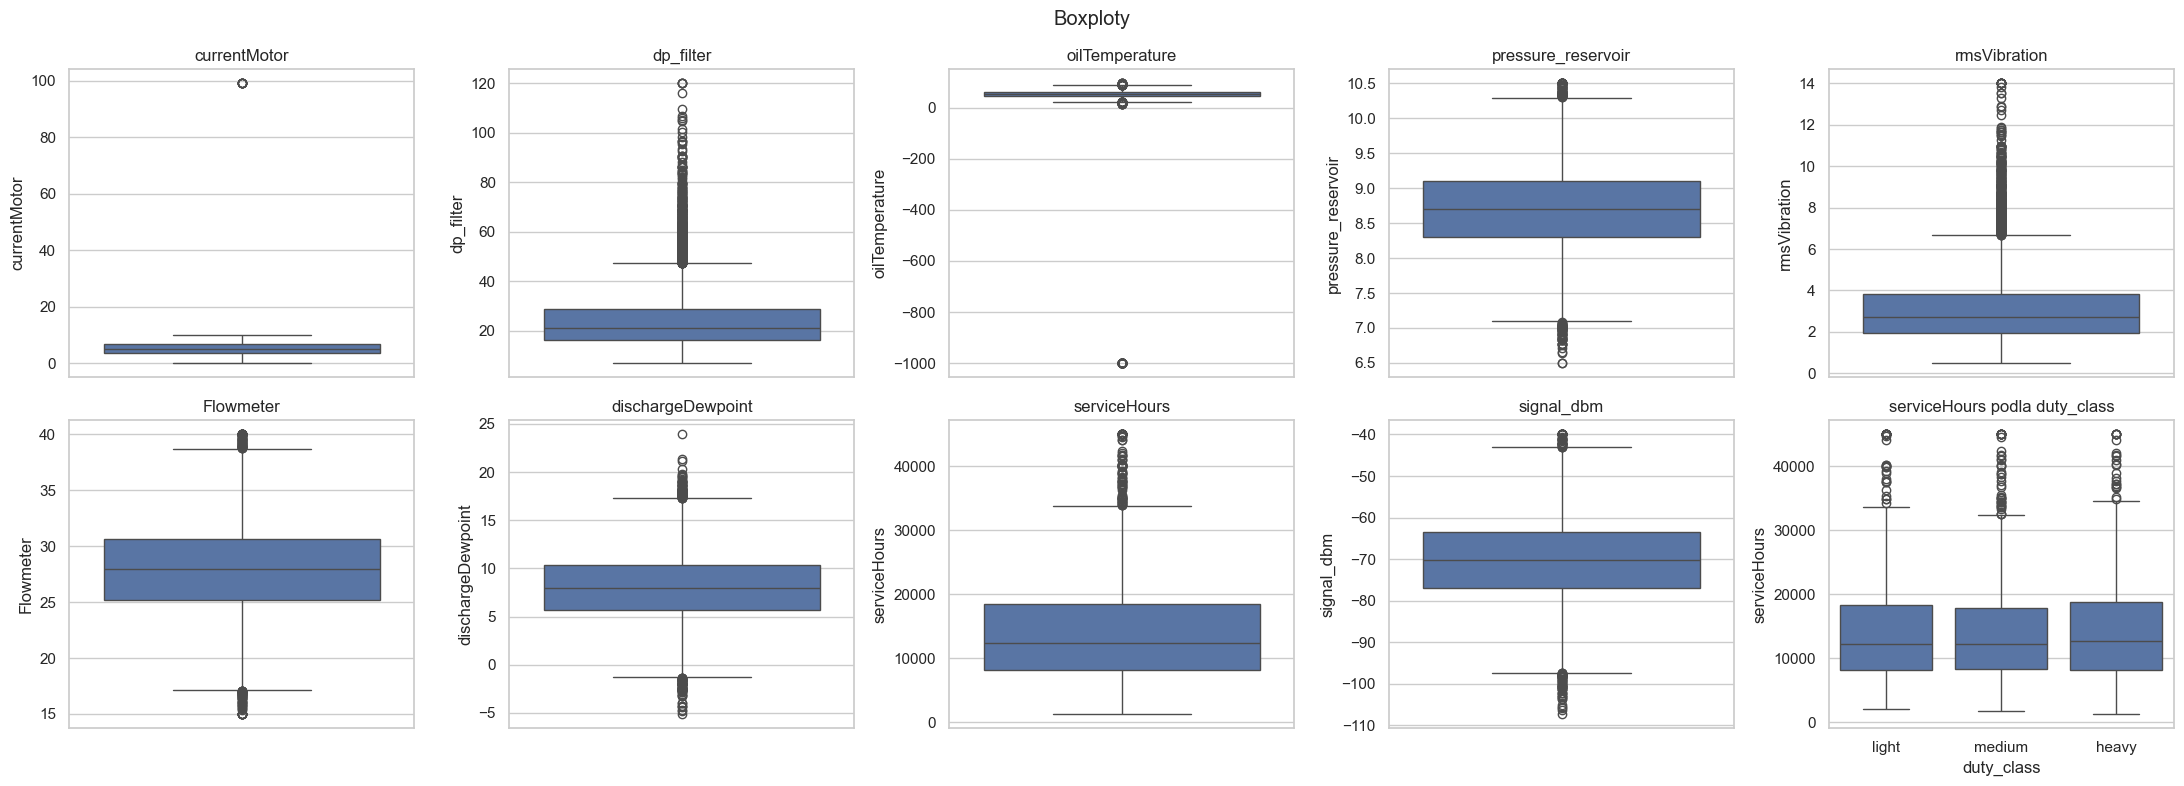

In [76]:
fig, axes = plt.subplots(2, 5, figsize=(22, 8))
axes = axes.ravel()

for ax, (df_, c) in zip(axes, attrs):
    sns.boxplot(y=df_[c], ax=ax)
    ax.set_title(c)

sns.boxplot(x='duty_class', y='serviceHours', data=data_3, order=['light', 'medium', 'heavy'], ax=axes[9])
axes[9].set_title('serviceHours podla duty_class')
plt.suptitle('Boxploty')
plt.tight_layout(); plt.show()

Boxploty potvrdzuju zistenia z histogramov

In [77]:
print('duty_class:')
display(data_3['duty_class'].value_counts().to_frame('count'))

duty_class:


,count
duty_class,
light,804
medium,686
heavy,510


duty_class uz bol vycisteny (v surovych datach malo 20 roznych zapisov, boli zlucene do 3 tried)

In [78]:
# Tabulka popisnych statistik
stats_list = []

for df, col in attrs:
    s = df[col]
    s_clean = s.dropna()
    
    q25 = s_clean.quantile(0.25)
    q75 = s_clean.quantile(0.75)
    
    stats_list.append({
        'Attribute': col,
        'Count': len(s),
        'Missing (NaN)': s.isnull().sum(),
        'Mean': round(s_clean.mean(), 2),
        'Std': round(s_clean.std(), 2),
        'Median': round(s_clean.median(), 2),
        'Min': round(s_clean.min(), 2),
        'Max': round(s_clean.max(), 2),
        'IQR': round(q75 - q25, 2),
        'Skewness': round(s_clean.skew(), 2)
    })

stats_df = pd.DataFrame(stats_list)
display(stats_df)

,Attribute,Count,Missing (NaN),Mean,Std,Median,Min,Max,IQR,Skewness
0,currentMotor,14052,0,5.28,2.89,5.13,0.12,99.0,2.91,19.37
1,dp_filter,14052,549,24.07,11.43,21.25,7.08,120.0,12.44,1.98
2,oilTemperature,14052,0,50.63,68.62,55.07,-999.00,95.0,16.28,-14.77
3,pressure_reservoir,14052,0,8.70,0.60,8.70,6.50,10.5,0.80,-0.02
4,rmsVibration,14052,518,3.08,1.64,2.72,0.50,14.0,1.89,1.65
5,Flowmeter,14052,0,27.93,4.01,27.94,15.00,40.0,5.41,-0.01
6,dischargeDewpoint,14052,0,7.97,3.51,7.97,-5.12,23.9,4.64,0.02
7,serviceHours,2000,100,14588.64,8953.21,12343.30,1303.00,45000.0,10250.52,1.38
8,signal_dbm,16000,0,-70.17,10.01,-70.20,-107.30,-40.0,13.60,0.00


#### Zhodnotenie rozsahov a anomalii:
* Atributy v norme: pressure_reservoir, Flowmeter, dischargeDewpoint, rmsVibration, dp_filter a signal_dbm splnaju ocakavane prevadzkove rozsahy.
* Identifikovane anomalie: oilTemperature: Minimum -999.0 predstavuje chybovy kod snimaca (sentinel). currentMotor: Maximum 99.0 je extrémne odlahla hodnota (outlier medianu 5.13). serviceHours: Maximum 45,000h naznačuje horny strop hodnot v systeme.

In [79]:
# Kontrola rozsahov a sentinelov
sentinel_candidates = [-999, -99, 99, 999]
range_check = []

for df, col in attrs:
    s = df[col]
    
    # Zistenie vyskytu sentinelov
    found_sentinels = {}
    for val in sentinel_candidates:
        cnt = (s == val).sum()
        if cnt > 0:
            found_sentinels[val] = cnt
            
    range_check.append({
        'Attribute': col,
        'Min': s.min(),
        'Max': s.max(),
        'Sentinels Found': found_sentinels if found_sentinels else "None",
        'NaN Count': s.isnull().sum()
    })

range_df = pd.DataFrame(range_check)
display(range_df)

,Attribute,Min,Max,Sentinels Found,NaN Count
0,currentMotor,0.11588,99.00000,{99: 8},0
1,dp_filter,7.08115,120.00000,None,549
2,oilTemperature,-999.00000,95.00000,{-999: 58},0
3,pressure_reservoir,6.50000,10.50000,None,0
4,rmsVibration,0.50000,14.00000,None,518
5,Flowmeter,15.00000,40.00000,None,0
6,dischargeDewpoint,-5.11782,23.90483,None,0
7,serviceHours,1303.00000,45000.00000,None,100
8,signal_dbm,-107.30000,-40.00000,{-99: 2},0


Analyza rozsahov a sentinelov:
* oilTemperature obsahuje hodnotu -999.0, co je chyba senzora/sentinel. Bude to treba nahradit za NaN. 
* currentMotor ma max hodnotu 99.0, co je odlahly bod oproti 75. percentilu (6.64).
* Chybajuce hodnoty (NaN): dp_filter (549), rmsVibration (518), serviceHours (100) a id_unit v gateways pre ID nad 2000.

## Rozdelenie parovej analyzy dat

### 1. Senzorove merania (Senzor vs. Senzor)
- **oilTemperature vs. rmsVibration** - Vztah medzi vibraciami a teplotou motoroveho oleja

### 2. Hardver a firmvér (Hardver vs. Firmvér)
- **hardware_model vs. versionFirmware** - porovnanie vyuzivania verzie firmveru v roznom hardvere

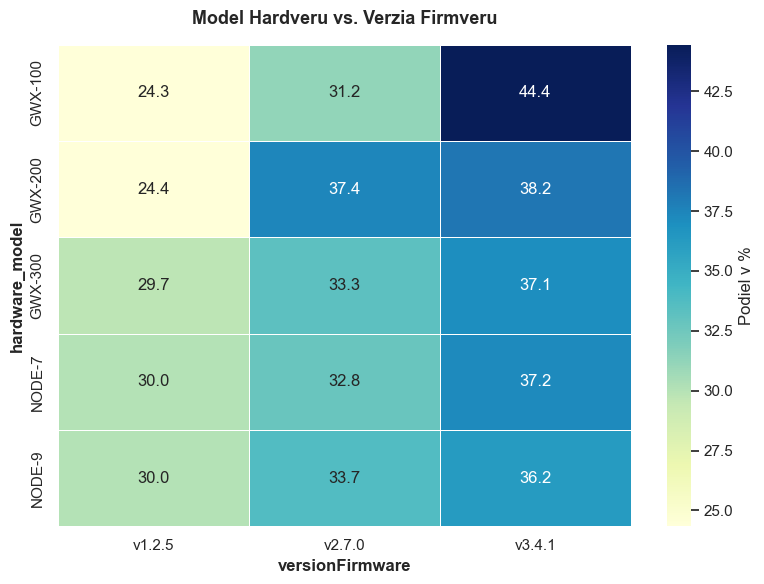

In [80]:
gateways = pd.read_csv('data/gateways.csv', sep=';', index_col='gateway_id')
units = pd.read_csv('data/units.csv', sep=',', index_col='id_unit')

# Prepojenie dat podlla id_unit
gateways_clean = gateways.dropna(subset=['id_unit']).copy()
gateways_clean['id_unit'] = gateways_clean['id_unit'].astype(int)
merged = gateways_clean.merge(units, left_on='id_unit', right_index=True, how='left')

# Kontingencna tabulka
ct = pd.crosstab(
    merged['hardware_model'], 
    merged['versionFirmware'], 
    normalize='index'
) * 100

# Vykreslenie heatmapy
plt.figure(figsize=(8, 6))
sns.set_theme(style="whitegrid")

sns.heatmap(
    ct, 
    annot=True, 
    fmt=".1f", 
    cmap='YlGnBu', 
    cbar_kws={'label': 'Podiel v %'}, 
    linewidths=0.5
)

plt.title('Model Hardveru vs. Verzia Firmveru', fontsize=13, fontweight='bold', pad=15)
plt.xlabel('versionFirmware', fontweight='bold')
plt.ylabel('hardware_model', fontweight='bold')

plt.tight_layout()
plt.show()

In [81]:
mala_tabulka = pd.crosstab(
    merged['hardware_model'], 
    merged['versionFirmware'], 
    normalize='index'
).round(3) * 100

display(mala_tabulka)

versionFirmware,v1.2.5,v2.7.0,v3.4.1
hardware_model,,,
GWX-100,24.3,31.2,44.4
GWX-200,24.4,37.4,38.2
GWX-300,29.7,33.3,37.1
NODE-7,30.0,32.8,37.2
NODE-9,30.0,33.7,36.2


### hardware_model vs. versionFirmware

* Staršie modely ako GWX-100 maju nizsie zastupenie najnovsej verzie firmvéru v3.4.1, zatial co pokrocilejsie modely a kategórie NODE maju vyssi podiel novsich verzii firmveru

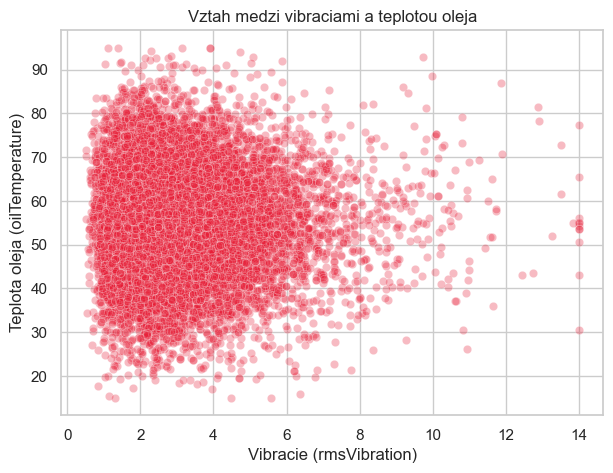

In [82]:
# Osetrenie chybnych hodnot (napriklad -999) pred vykreslenim
data_2['oilTemp_clean'] = data_2['oilTemperature'].replace(-999, np.nan)

# graf zavislosti
plt.figure(figsize=(7, 5))
sns.scatterplot(data=data_2, x='rmsVibration', y='oilTemp_clean', alpha=0.3, color='#e71d36')
plt.title('Vztah medzi vibraciami a teplotou oleja')
plt.xlabel('Vibracie (rmsVibration)')
plt.ylabel('Teplota oleja (oilTemperature)')
plt.show()

In [83]:
corr_oil_vib = data_2[['oilTemp_clean', 'rmsVibration']].corr().round(1)
display(corr_oil_vib)

,oilTemp_clean,rmsVibration
oilTemp_clean,1.0,-0.0
rmsVibration,-0.0,1.0


### oilTemperature vs. rmsVibration

* Korelacny koeficient: r = 0.0
* Rozlozenie bodov: Po odstraneni chybnych hodnot su body rovnomerne rozptylene

Zaver: Napriek ocakavanej zavislosti medzi vibraciami a teplotou motoroveho oleja sa v datach nezistil ziadny vztah - zrejme ide o nezavisle nasnimane parametre

## Parova analyza predikovanej premennej

### Zavislosti predikovanej premennej (Failure vs. Prediktory)
- **Failure vs. dp_filter** - Vplyv zaneseneho filtra na vznik poruchy
- **Failure vs. serviceHours** - Vplyv opotrebovania stroja na poruchovost

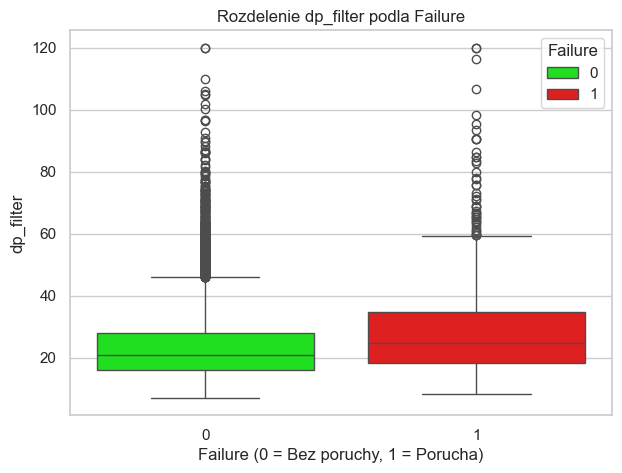

In [84]:
plt.figure(figsize=(7, 5))
sns.boxplot(
    data=data_2,
    x='Failure',
    y='dp_filter',
    hue='Failure',
    palette=["#00FF00", '#ff0000']
)
plt.title('Rozdelenie dp_filter podla Failure')
plt.xlabel('Failure (0 = Bez poruchy, 1 = Porucha)')
plt.ylabel('dp_filter')
plt.show()

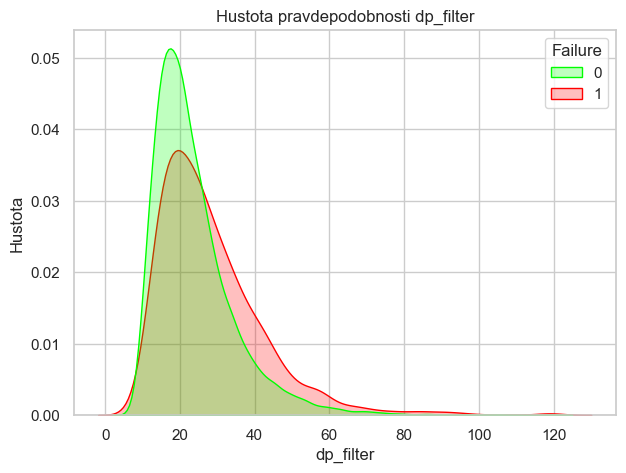

In [85]:
plt.figure(figsize=(7, 5))
sns.kdeplot(
    data=data_2,
    x='dp_filter',
    hue='Failure',
    common_norm=False,
    fill=True,
    palette=['#00FF00', '#ff0000']
)
plt.title('Hustota pravdepodobnosti dp_filter')
plt.xlabel('dp_filter')
plt.ylabel('Hustota')
plt.show()

In [86]:
stats_dp = data_2.groupby('Failure')['dp_filter'].agg(['count', 'mean', 'median', 'std', 'min', 'max']).round(1)
display(stats_dp)

,count,mean,median,std,min,max
Failure,,,,,,
0,12142,23.6,21.0,11.0,7.1,120.0
1,1361,28.4,24.9,14.3,8.2,120.0


* Vyssie hodnoty pri poruche: Pri zlyhani stroja je median dp_filter vyssi (24.904) v porovnani s beznou prevadzkou (20.953). Rovnako stupa priemer z 23.588 na 28.403
* Rozdelenie dat: Graf hustoty aj boxplot ukazuju posun rozdelenia doprava smerom k vyssim hodnotam pri poruchovych stavoch
* Variabilita: Pri poruche je sledovana aj vyssia smerodajna odchylka (14.274 vs 10.966), co znaci vacsiu nestabilitu tlaku na filtri

Medzi dp_filter a Failure existuje pozitivna zavislost. Zvyseny tlakovy spad indikuje zanesenie filtra, co priamo zvysuje riziko poruchy stroja

In [87]:
# prepojenie tabuliek data_2 a data_3 cez id_unit
data_2['id_unit_num'] = data_2['id_unit'].str[1:].astype(int)
df_merged = data_2.merge(data_3, left_on='id_unit_num', right_index=True)

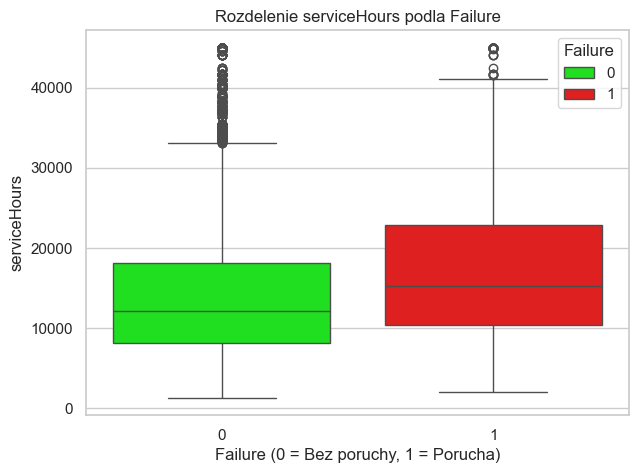

In [88]:
plt.figure(figsize=(7, 5))
sns.boxplot(
    data=df_merged,
    x='Failure',
    y='serviceHours',
    hue='Failure',
    palette=['#00FF00', '#ff0000']
)
plt.title('Rozdelenie serviceHours podla Failure')
plt.xlabel('Failure (0 = Bez poruchy, 1 = Porucha)')
plt.ylabel('serviceHours')
plt.show()

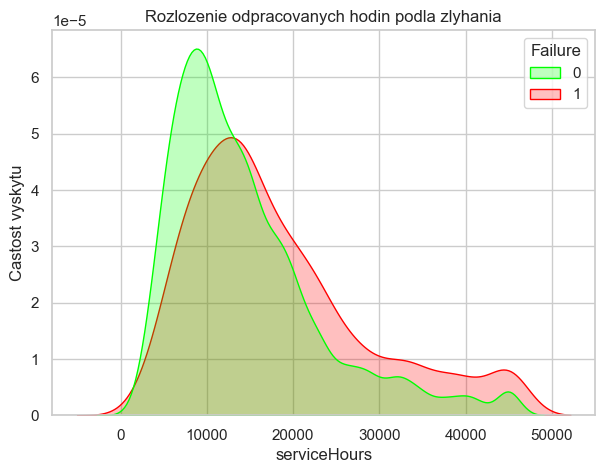

In [89]:
plt.figure(figsize=(7, 5))
sns.kdeplot(
    data=df_merged,
    x='serviceHours',
    hue='Failure',
    common_norm=False,
    fill=True,
    palette=['#00FF00', '#ff0000']
)
plt.title('Rozlozenie odpracovanych hodin podla zlyhania')
plt.xlabel('serviceHours')
plt.ylabel('Castost vyskytu')
plt.show()

In [90]:
stats_sh = df_merged.groupby('Failure')['serviceHours'].agg(['count', 'mean', 'median', 'std', 'min', 'max']).round(1)
display(stats_sh)

,count,mean,median,std,min,max
Failure,,,,,,
0,11657,14321.6,12167.1,8724.4,1303.0,45000.0
1,1588,18150.2,15211.6,10372.9,2078.5,45000.0


* Vyssi pocet odpracovanych hodin pri poruche: Pri zlyhani stroja je median serviceHours vyssi (15211.6) v porovnani s beznou prevadzkou (12167.1). Priemer stupa z 14321.6 na 18150.2 hodin
* Rozdelenie dat: Graf hustoty ukazuje, ze pri vyssom pocte odpracovanych hodin (nad ~15 000 h) sa podiel poruch vyrazne zvysuje
* Variabilita: Smerodajna odchylka je pri poruchovych stavoch vyssia (10372.913 vs 8724.430), co ukazuje na roznorody vek kaziacich sa strojov

Medzi serviceHours a Failure existuje pozitivna zavislost. Pouzivanie stroja priamo zvysuje pravdepodobnost poruchy

## Dokumentacia prvotneho zamyslenia k rieseniu zadania

### 1. Spajanie dat z viacerych suborov
* **Nutnost spajania:** Ano, pre riesenie zadania je dolezite skombinovat zaznamy zo vsetkych troch suborov (gateways.csv, readings.csv, units.csv)
* **Sposob prepojenia:** Data sa spajaju cez identifikator jednotky (id_unit / gateway ID)
* **Dovod:** Jednotlive subory obsahuju rozne vrstvy dat. Napriklad readings.csv obsahuje prevadzkove merania zo senzorov a stav poruchy (Failure), units.csv obsahuje hardverove parametre (year_commission, duty_class, serviceHours) a gateways.csv obsahuje informacie o komunikacnych moduloch. Pre kompletnu analyzu musime mat vsetky vlastnosti v jednej tabulke

### 2. Zavislosti medzi samotnymi atributmi
**Co uz vieme z doterajsej analyzy**
* oilTemperature vs. rmsVibration: po odstraneni sentinelu -999 vychadza r = 0, teda napriek ocakavaniu medzi nimi nie je linearna zavislost
* hardware_model vs. versionFirmware: podiely verzii firmveru sa medzi modelmi lisia, takze tieto dva kategoricke atributy su na sebe zavisle
**Logicke zavislosti, ktore ocakavame a overujeme**
* serviceHours a year_commission: starsie jednotky by mali mat viac odpracovanych hodin
* serviceHours a duty_class: tazsia zataz znamena viac hodin

### 3. Od ktorych atributov zavisi predikovana premenna (`Failure`)
**Co uz vieme:** pri poruche je vyssi dp_filter (median 24.9 vs. 21.0) aj serviceHours (median 15 212 vs. 12 167). Vyssie to overujeme systematicky pre vybrane atributy.

Pouzivame **Mann-Whitneyho test** a **Spearmanovu korelaciu s Failure** (obe su vhodne pre sikme rozdelenia a nepredpokladaju normalitu), pri kategorickych atributoch **chi-kvadrat test** a **Cramerovo V** ako velkost zavislosti. Pri velkom pocte riadkov (14 tisic) vychadza p-hodnota vyznamna aj pri zanedbatelnom efekte, preto sa pozerame hlavne na velkost efektu, nie len na p.

## 1.2 Identifikácia problémov, integrácia a čistenie dát
Problemy zistene v predchazajucej faze:

gateways: 
- Nekonzistentné pomenovanie atribútov, napríklad: seen_last, Lon, versionFirmware, Technician
- gateway_id - nesprávny formát, malo by to byť celé číslo, nie reťazec
- seen_last	-  nekonzistentný formát času
- install_date - nekonzistentný formát času
- id_unit	-  má ho len 2000 vzoriek, ostatných 14 000 má hodnotu NaN; malo by to byť celé číslo, nie desatinné číslo

readings:
- Nekonzistentné pomenovanie atribútov
- id_unit - nesprávny formát, malo by to byť celé číslo, nie reťazec
- cycle_ts - formát času nie je konzistentný
- dp_filter a rmsVibration obsahuju NaN hodnoty
- oilTemperature -min je -999,000000, čo nie je logické, problém v údajoch

units: 
- Nekonzistentné pomenovanie atribútov
- duty_class má nejednotné názvy kategórií 20, malo by byť 3 [1-light, 2-medium, 3-heavy]
- overhaul_last - formát času nie je konzistentný
- serviceHours - má 100 NaN hôdnot

In [4]:
data_1 = pd.read_csv(filename_1, 
                   sep=';', index_col=13)
data_1.head()

,seen_last,install_date,Lon,idDepot,macAddress,versionFirmware,signal_dbm,lat,Vendor,hardware_model,id_unit,Technician,ipv4
gateway_id,,,,,,,,,,,,,
GW-00000,2024-04-08,"10/03/2023, 00:00:00",-8.89921,112,e2:f9:05:83:4d:20,v2.7.0,-66.2,38.91850,Fritsch,GWX-200,1831.0,Elenore Herrmann,67.49.73.170
GW-00001,"11/07/2024, 00:00:00","07/11/2016, 00:00:00",-7.87246,88,6d:a5:2b:72:5b:10,v1.2.5,-75.7,39.79636,Nogueira,GWX-100,488.0,Bradley Fleming,16.98.36.57
GW-00002,"10/02/2024, 00:00:00","05/04/2016, 00:00:00",-8.66738,85,ac:73:9a:fb:a3:73,v1.2.5,-71.4,38.82073,Leite,NODE-7,231.0,Sofia Loureiro,80.107.147.21
GW-00003,2025-01-24,2018-08-29,-6.64779,116,0f:21:99:19:d3:cb,v1.2.5,-76.6,41.01462,Speer,GWX-100,396.0,Michael Navarro,216.20.189.94
GW-00004,03 Aug 2024,2024/03/14,-8.80419,26,a7:13:08:aa:79:70,v2.7.0,-59.8,38.86962,Paiva Leite Lda.,NODE-9,1502.0,Ivan Branco,248.247.103.90


In [6]:
data_1 = data_1.rename({'Lon' : 'lon', 'idDepot' :'id_deport','macAddress' : 'mac_addr', 'version_firmware' : 'firmware', 'Vendor' : 'vendor', 'Technician' : 'technician'}, axis='columns')
data_1.head()

,seen_last,install_date,lon,id_deport,mac_addr,versionFirmware,signal_dbm,lat,vendor,hardware_model,id_unit,technician,ipv4
gateway_id,,,,,,,,,,,,,
GW-00000,2024-04-08,"10/03/2023, 00:00:00",-8.89921,112,e2:f9:05:83:4d:20,v2.7.0,-66.2,38.91850,Fritsch,GWX-200,1831.0,Elenore Herrmann,67.49.73.170
GW-00001,"11/07/2024, 00:00:00","07/11/2016, 00:00:00",-7.87246,88,6d:a5:2b:72:5b:10,v1.2.5,-75.7,39.79636,Nogueira,GWX-100,488.0,Bradley Fleming,16.98.36.57
GW-00002,"10/02/2024, 00:00:00","05/04/2016, 00:00:00",-8.66738,85,ac:73:9a:fb:a3:73,v1.2.5,-71.4,38.82073,Leite,NODE-7,231.0,Sofia Loureiro,80.107.147.21
GW-00003,2025-01-24,2018-08-29,-6.64779,116,0f:21:99:19:d3:cb,v1.2.5,-76.6,41.01462,Speer,GWX-100,396.0,Michael Navarro,216.20.189.94
GW-00004,03 Aug 2024,2024/03/14,-8.80419,26,a7:13:08:aa:79:70,v2.7.0,-59.8,38.86962,Paiva Leite Lda.,NODE-9,1502.0,Ivan Branco,248.247.103.90


In [7]:
data_1.index = data_1.index.str[3:].astype(int)
data_1.index.name = "gateway_id"

In [9]:
data_1.seen_last.head(20)

gateway_id
0               2024-04-08
1     11/07/2024, 00:00:00
2     10/02/2024, 00:00:00
3               2025-01-24
4              03 Aug 2024
5     10/20/2024, 00:00:00
6               2024-08-10
7               2024/04/24
8     12/25/2024, 00:00:00
9     04/03/2024, 00:00:00
10             16 Oct 2024
11    06/19/2024, 00:00:00
12              2024-04-13
13    10/12/2024, 00:00:00
14              2024-08-01
15    10/28/2024, 00:00:00
16              2024/12/10
17              2024-11-01
18              2024/04/11
19              2025-01-02
Name: seen_last, dtype: str

In [10]:
formats = ["%Y-%m-%d", "%Y/%m/%d", "%d %b %Y", "%m/%d/%Y, %H:%M:%S"]

def parse_dates(col):
    s = col.astype(str).str.strip()
    out = pd.Series(pd.NaT, index=s.index, dtype="datetime64[ns]")
    for fmt in formats:
        out = out.fillna(pd.to_datetime(s, format=fmt, errors="coerce"))
    return out

In [11]:
for c in ["install_date", "seen_last"]:
    data_1[c] = parse_dates(data_1[c])

In [12]:
s = data_1["install_date"].astype(str).str.strip()
print(s[parse_dates(s).isna()])

Series([], Name: install_date, dtype: str)


In [13]:
s = data_1["seen_last"].astype(str).str.strip()
print(s[parse_dates(s).isna()])

Series([], Name: seen_last, dtype: str)


In [14]:
data_1["install_date"] = data_1["install_date"].dt.strftime("%Y-%m-%d")

In [15]:
data_1["seen_last"] = data_1["seen_last"].dt.strftime("%Y-%m-%d")

In [16]:
data_1.head()   

,seen_last,install_date,lon,id_deport,mac_addr,versionFirmware,signal_dbm,lat,vendor,hardware_model,id_unit,technician,ipv4
gateway_id,,,,,,,,,,,,,
0,2024-04-08,2023-10-03,-8.89921,112,e2:f9:05:83:4d:20,v2.7.0,-66.2,38.91850,Fritsch,GWX-200,1831.0,Elenore Herrmann,67.49.73.170
1,2024-11-07,2016-07-11,-7.87246,88,6d:a5:2b:72:5b:10,v1.2.5,-75.7,39.79636,Nogueira,GWX-100,488.0,Bradley Fleming,16.98.36.57
2,2024-10-02,2016-05-04,-8.66738,85,ac:73:9a:fb:a3:73,v1.2.5,-71.4,38.82073,Leite,NODE-7,231.0,Sofia Loureiro,80.107.147.21
3,2025-01-24,2018-08-29,-6.64779,116,0f:21:99:19:d3:cb,v1.2.5,-76.6,41.01462,Speer,GWX-100,396.0,Michael Navarro,216.20.189.94
4,2024-08-03,2024-03-14,-8.80419,26,a7:13:08:aa:79:70,v2.7.0,-59.8,38.86962,Paiva Leite Lda.,NODE-9,1502.0,Ivan Branco,248.247.103.90


In [17]:
data_1["id_unit"] = data_1["id_unit"].astype("Int64")
data_1.head()

,seen_last,install_date,lon,id_deport,mac_addr,versionFirmware,signal_dbm,lat,vendor,hardware_model,id_unit,technician,ipv4
gateway_id,,,,,,,,,,,,,
0,2024-04-08,2023-10-03,-8.89921,112,e2:f9:05:83:4d:20,v2.7.0,-66.2,38.91850,Fritsch,GWX-200,1831,Elenore Herrmann,67.49.73.170
1,2024-11-07,2016-07-11,-7.87246,88,6d:a5:2b:72:5b:10,v1.2.5,-75.7,39.79636,Nogueira,GWX-100,488,Bradley Fleming,16.98.36.57
2,2024-10-02,2016-05-04,-8.66738,85,ac:73:9a:fb:a3:73,v1.2.5,-71.4,38.82073,Leite,NODE-7,231,Sofia Loureiro,80.107.147.21
3,2025-01-24,2018-08-29,-6.64779,116,0f:21:99:19:d3:cb,v1.2.5,-76.6,41.01462,Speer,GWX-100,396,Michael Navarro,216.20.189.94
4,2024-08-03,2024-03-14,-8.80419,26,a7:13:08:aa:79:70,v2.7.0,-59.8,38.86962,Paiva Leite Lda.,NODE-9,1502,Ivan Branco,248.247.103.90


Vyriesene problemy v `data_1`: nazvy attributov - zmena na konzistentne, uprava formatu `gateway_id` a `id_unit`, zmena formatu datumov na konzistentne v `seen_last` a	`install_date`

In [18]:
data_2 = pd.read_csv(filename_2, 
                    sep='\t')
data_2.head()

,id_unit,cycle_ts,currentMotor,dp_filter,oilTemperature,pressure_reservoir,rmsVibration,Flowmeter,dischargeDewpoint,Failure
0,U00078,24 Sep 2023,2.91072,17.08727,63.17362,10.42780,5.53225,24.90723,5.49963,0
1,U01922,2023-10-05,5.20071,14.68177,36.67755,8.84326,6.40699,26.62476,7.60072,1
2,U00548,2023-10-18,5.56161,44.22325,43.50675,8.03135,4.30464,26.39225,5.25673,0
3,U01551,21 Mar 2023,5.12227,21.50330,63.91073,7.86316,1.66650,22.98348,5.09449,1
4,U00298,04 Oct 2023,5.11036,29.84890,64.71004,9.78952,2.82960,33.75524,11.50507,0


In [19]:
data_2=data_2.rename({'currentMotor' : 'curr_motor', 'oilTemperature' : 'oil_temp','pressure_reservoir' : 'press_reserv','rmsVibration' : 'rms_vibration', 'Flowmeter' : 'flow', 'dischargeDewpoint' : 'dis_dewp', 'Failure' : 'fail'}, axis='columns') 
data_2.head()

,id_unit,cycle_ts,curr_motor,dp_filter,oil_temp,press_reserv,rms_vibration,flow,dis_dewp,fail
0,U00078,24 Sep 2023,2.91072,17.08727,63.17362,10.42780,5.53225,24.90723,5.49963,0
1,U01922,2023-10-05,5.20071,14.68177,36.67755,8.84326,6.40699,26.62476,7.60072,1
2,U00548,2023-10-18,5.56161,44.22325,43.50675,8.03135,4.30464,26.39225,5.25673,0
3,U01551,21 Mar 2023,5.12227,21.50330,63.91073,7.86316,1.66650,22.98348,5.09449,1
4,U00298,04 Oct 2023,5.11036,29.84890,64.71004,9.78952,2.82960,33.75524,11.50507,0


In [20]:
data_2["id_unit"] = data_2["id_unit"].str[1:].astype(int)

In [21]:
data_2.head()

,id_unit,cycle_ts,curr_motor,dp_filter,oil_temp,press_reserv,rms_vibration,flow,dis_dewp,fail
0,78,24 Sep 2023,2.91072,17.08727,63.17362,10.42780,5.53225,24.90723,5.49963,0
1,1922,2023-10-05,5.20071,14.68177,36.67755,8.84326,6.40699,26.62476,7.60072,1
2,548,2023-10-18,5.56161,44.22325,43.50675,8.03135,4.30464,26.39225,5.25673,0
3,1551,21 Mar 2023,5.12227,21.50330,63.91073,7.86316,1.66650,22.98348,5.09449,1
4,298,04 Oct 2023,5.11036,29.84890,64.71004,9.78952,2.82960,33.75524,11.50507,0


In [22]:
data_2["cycle_ts"] = parse_dates(data_2["cycle_ts"])

In [23]:
print(data_2["cycle_ts"].isna().sum())

0


In [24]:
s = data_2["cycle_ts"].astype(str).str.strip()
print(s[parse_dates(s).isna()].unique())

<ArrowStringArray>
['2023-09-24 00:00:00', '2023-10-05 00:00:00', '2023-10-18 00:00:00',
 '2023-03-21 00:00:00', '2023-10-04 00:00:00', '2023-12-12 00:00:00',
 '2023-04-23 00:00:00', '2023-03-24 00:00:00', '2023-01-02 14:07:00',
 '2023-03-17 00:00:00',
 ...
 '2023-09-17 00:59:00', '2023-09-09 00:32:00', '2023-01-30 03:02:00',
 '2023-08-16 06:18:00', '2023-03-13 09:16:00', '2023-07-27 11:07:00',
 '2023-04-20 08:25:00', '2023-04-12 15:20:00', '2023-09-28 05:01:00',
 '2023-06-22 08:15:00']
Length: 3845, dtype: str


In [27]:
data_2.head()

,id_unit,cycle_ts,curr_motor,dp_filter,oil_temp,press_reserv,rms_vibration,flow,dis_dewp,fail
0,78,2023-09-24,2.91072,17.08727,63.17362,10.42780,5.53225,24.90723,5.49963,0
1,1922,2023-10-05,5.20071,14.68177,36.67755,8.84326,6.40699,26.62476,7.60072,1
2,548,2023-10-18,5.56161,44.22325,43.50675,8.03135,4.30464,26.39225,5.25673,0
3,1551,2023-03-21,5.12227,21.50330,63.91073,7.86316,1.66650,22.98348,5.09449,1
4,298,2023-10-04,5.11036,29.84890,64.71004,9.78952,2.82960,33.75524,11.50507,0


Vyriesene problemy v `data_2`:  nazvy attributov - zmena na konzistentne, uprava formatu  `id_unit`, zmena formatu datumov na konzistentne v `cycle_ts`

In [28]:
data_3 = pd.read_csv(filename_3, 
                    sep=',',index_col=5
                    )
data_3.head()

,idDepot,duty_class,year_commission,serviceHours,overhaul_last,serial_number
id_unit,,,,,,
1,97,light,2022,7263.7,"09/23/2021, 00:00:00",GQ-0521-56531
2,81,heavy,2023,6053.4,2020-05-07,HN-5203-27688
3,56,light,2023,4921.4,2021/06/04,QC-5243-50182
4,53,3,2018,21803.6,25 Apr 2021,TC-5483-81500
5,54,normal,2020,15730.5,"08/13/2024, 00:00:00",XO-0640-55128


In [29]:
data_3['duty_class'] = (
    data_3['duty_class']
    .str.strip()
    .replace({
        '1': '1',
        'L': '1',
        'light': '1',

        '2': '2',
        'med': '2',
        'N': '2',
        'normal': '2',

        '3': '3',
        'H': '3',
        'heavy': '3'
    })
)

In [31]:
data_3 = data_3.rename({'idDepot' : 'id_deport', 'year_commission' : 'y_commission', 'serviceHours' : 'serv_hours', 'serial_number' : 'serial_num'}, axis='columns')
data_3.head()

,id_deport,duty_class,y_commission,serv_hours,overhaul_last,serial_num
id_unit,,,,,,
1,97,1,2022,7263.7,"09/23/2021, 00:00:00",GQ-0521-56531
2,81,3,2023,6053.4,2020-05-07,HN-5203-27688
3,56,1,2023,4921.4,2021/06/04,QC-5243-50182
4,53,3,2018,21803.6,25 Apr 2021,TC-5483-81500
5,54,2,2020,15730.5,"08/13/2024, 00:00:00",XO-0640-55128


In [32]:
data_3["overhaul_last"] = parse_dates(data_3["overhaul_last"])
print(data_3["overhaul_last"].isna().sum())

0


In [33]:
data_3.head()  

,id_deport,duty_class,y_commission,serv_hours,overhaul_last,serial_num
id_unit,,,,,,
1,97,1,2022,7263.7,2021-09-23,GQ-0521-56531
2,81,3,2023,6053.4,2020-05-07,HN-5203-27688
3,56,1,2023,4921.4,2021-06-04,QC-5243-50182
4,53,3,2018,21803.6,2021-04-25,TC-5483-81500
5,54,2,2020,15730.5,2024-08-13,XO-0640-55128


Vyriesene problemy v `data_3`:  nazvy attributov - zmena na konzistentne, uprava `duty_class` types z 20 na 3 (1-light, 2-medium, 3-heavy) lebo boli mistyped typy, zmena formatu datumov na konzistentne v `overhaul_last`

In [34]:
data_3.describe()

,id_deport,y_commission,serv_hours,overhaul_last
count,2000.000000,2000.000000,1900.000000,2000
mean,54.737500,2020.343000,14588.644842,2019-12-25 15:35:59.999999744
min,0.000000,2012.000000,1303.000000,2015-01-01 00:00:00
25%,24.000000,2019.000000,8224.525000,2017-06-06 00:00:00
50%,53.000000,2021.000000,12343.300000,2019-12-31 00:00:00
75%,83.000000,2022.000000,18475.050000,2022-06-21 18:00:00
max,119.000000,2024.000000,45000.000000,2024-12-26 00:00:00
std,34.325074,2.547076,8953.209427,NaN


In [35]:
from sklearn.impute import KNNImputer
imputed = KNNImputer(n_neighbors=5).fit_transform(data_3[["y_commission", "serv_hours"]])
data_3["serv_hours"] = imputed[:, 1]

In [36]:
data_3.describe()

,id_deport,y_commission,serv_hours,overhaul_last
count,2000.000000,2000.000000,2000.000000,2000
mean,54.737500,2020.343000,14579.541220,2019-12-25 15:35:59.999999744
min,0.000000,2012.000000,1303.000000,2015-01-01 00:00:00
25%,24.000000,2019.000000,8272.475000,2017-06-06 00:00:00
50%,53.000000,2021.000000,12612.000000,2019-12-31 00:00:00
75%,83.000000,2022.000000,18461.575000,2022-06-21 18:00:00
max,119.000000,2024.000000,45000.000000,2024-12-26 00:00:00
std,34.325074,2.547076,8925.288392,NaN


Pri zisteni: **y_commission** má so **serv_hours** korelaciu -0,96, čo je veľmi silný vzťah. Sme pouzili kNN a s jedným príznakom.

In [37]:
data_3.head()

,id_deport,duty_class,y_commission,serv_hours,overhaul_last,serial_num
id_unit,,,,,,
1,97,1,2022,7263.7,2021-09-23,GQ-0521-56531
2,81,3,2023,6053.4,2020-05-07,HN-5203-27688
3,56,1,2023,4921.4,2021-06-04,QC-5243-50182
4,53,3,2018,21803.6,2021-04-25,TC-5483-81500
5,54,2,2020,15730.5,2024-08-13,XO-0640-55128


In [38]:
print(data_3[data_3["serv_hours"] > 35000])

         id_deport duty_class  y_commission  serv_hours overhaul_last  \
id_unit                                                                 
16              95          2          2012     45000.0    2020-08-11   
27              22          1          2012     45000.0    2022-12-24   
45              80          3          2014     36708.1    2017-12-11   
100             23          1          2013     38938.2    2016-10-01   
105             36          1          2012     45000.0    2020-09-08   
...            ...        ...           ...         ...           ...   
1894           116          3          2012     44124.6    2022-09-17   
1896            14          3          2013     41009.1    2016-12-24   
1927           113          3          2013     39028.9    2022-09-11   
1938            79          2          2013     41108.5    2024-11-11   
1991            33          1          2012     45000.0    2016-02-06   

            serial_num  
id_unit                 


In [39]:
print((data_3["serv_hours"] == 45000).sum())
print(data_3.loc[data_3["serv_hours"] == 45000, "y_commission"].value_counts())

29
y_commission
2012    29
Name: count, dtype: int64


Na strope 45 000 je 29 riadkov a všetky sú z roku 2012. 29 riadkov je z celkových 2000 len 1,5 %, takže ide o malý podiel. Zároveň stroje z roku 2012 majú očividne reálne hodiny aspoň 45 000, nie presne 45 000. Pri 1,5 % nie je dôvod zasahovať. Hodnoty zostanú ako sú.

In [123]:
bad = data_3[data_3["overhaul_last"].dt.year < data_3["y_commission"]]
print(len(bad), "z", len(data_3))

1100 z 2000


In [124]:
yr = data_3["overhaul_last"].dt.year
print(yr.corr(data_3["y_commission"], method="spearman"))
print((data_3["y_commission"] - yr).describe())

0.036697774021541736
count    2000.000000
mean        0.869500
std         3.797589
min       -12.000000
25%        -2.000000
50%         1.000000
75%         4.000000
max         9.000000
dtype: float64


Analýza odhalila, že 1 100 z 2 000 záznamov (55 %) obsahuje hodnotu overhaul_last zodpovedajúcu roku pred uvedením do prevádzky (y_commission). Spearmanova korelácia dosahuje iba 0,037 a rozdiel rokov sa pohybuje od −12 do +9. Výsledky naznačujú, že tieto premenné spolu prakticky nesúvisia a môže ísť o chybu pri zbere alebo anotácii dát. Keďže nie je možné spoľahlivo určiť správne hodnoty, oprava ani doplnenie údajov nie sú opodstatnené.

In [ ]:
age_h = (2024.99 - data_3["y_commission"]) * 8760
bad_hours = data_3["serv_hours"] > age_h
print(bad_hours.sum())
print(data_3.loc[bad_hours, ["y_commission", "serv_hours"]].head(10)) # to delete

0
Empty DataFrame
Columns: [y_commission, serv_hours]
Index: []


In [42]:
print(data_3.duplicated().sum())
print(data_3.index.duplicated().sum())
print(data_3["serial_num"].duplicated().sum())
print((~data_3["serial_num"].str.match(r"^[A-Z]{2}-\d{4}-\d{5}$")).sum())
print(data_3["duty_class"].value_counts())
print(data_3["id_deport"].between(0, 119).all())

0
0
0
0
duty_class
1    804
2    686
3    510
Name: count, dtype: int64
True


In [43]:
data_3.to_csv("./data/Ciste_data/data_3_clean.csv")

V data_3 neboli zistené duplicity. Zistené problémy: 100 chýbajúcich hodnôt serv_hours (doplnené mediánom podľa y_commission), strop 45 000 v serv_hours (29 záznamov z roku 2012, ponechané) a nelogický vzťah overhaul_last voči y_commission (55 % záznamov).

In [44]:
data_2.describe()

,id_unit,cycle_ts,curr_motor,dp_filter,oil_temp,press_reserv,rms_vibration,flow,dis_dewp,fail
count,14052.000000,14052,14052.000000,13503.000000,14052.000000,14052.000000,13534.000000,14052.000000,14052.000000,14052.000000
mean,1881.033020,2023-07-01 06:22:24.978650624,5.277158,24.073502,50.628361,8.698509,3.083622,27.925684,7.971619,0.118844
min,1.000000,2023-01-01 00:00:00,0.115880,7.081150,-999.000000,6.500000,0.500000,15.000000,-5.117820,0.000000
25%,499.000000,2023-04-01 00:00:00,3.731485,16.246110,46.753862,8.298048,1.936292,25.222520,5.666065,0.000000
50%,1015.000000,2023-07-02 00:00:00,5.127835,21.249320,55.072740,8.696900,2.718050,27.936505,7.972520,0.000000
75%,1515.000000,2023-09-30 14:31:00,6.643298,28.690820,63.030540,9.102232,3.830090,30.630375,10.308608,0.000000
max,90499.000000,2023-12-31 21:42:00,99.000000,120.000000,95.000000,10.500000,14.000000,40.000000,23.904830,1.000000
std,8851.623127,NaN,2.893927,11.434870,68.623763,0.601964,1.643651,4.007567,3.507052,0.323617


In [45]:
print(data_2[["dp_filter", "rms_vibration"]].isna().sum())
print(data_2[["dp_filter", "rms_vibration"]].isna().mean())
print(data_2.groupby("fail")[["dp_filter", "rms_vibration"]].apply(lambda g: g.isna().mean()))

dp_filter        549
rms_vibration    518
dtype: int64
dp_filter        0.039069
rms_vibration    0.036863
dtype: float64
      dp_filter  rms_vibration
fail                          
0      0.019383       0.019625
1      0.185030       0.164671


Analýza ukázala, že chýbajúce hodnoty v stĺpcoch dp_filter a rms_vibration sa vyskytujú približne 9-krát častejšie pri poruchách než pri bežnej prevádzke, čo naznačuje, že ich chýbanie nie je náhodné. Preto je vhodné vytvoriť indikátory chýbajúcich hodnôt.

In [46]:
for c in ["dp_filter", "rms_vibration"]:
    data_2[c] = data_2[c].fillna(data_2.groupby("fail")[c].transform("median"))

Doplnene mediánom v rámci skupiny `fail`

In [47]:
print((data_2["oil_temp"] == -999).sum())
print((data_2["curr_motor"] == 99).sum(), (data_2["dp_filter"] == 120).sum())
print((data_2["id_unit"] > 2000).sum())
print(data_2.loc[data_2["id_unit"] > 2000, "id_unit"].unique()[:20])

58
8 4
139
[90462 90271 90285 90435 90288 90463 90099 90122 90146 90366 90220 90246
 90431 90152 90133 90048 90249 90191 90281 90400]


In [48]:
bad = data_2["id_unit"] > 2000
print(data_2.loc[bad, "id_unit"].min(), data_2.loc[bad, "id_unit"].max())
fixed = data_2.loc[bad, "id_unit"] - 90000
print(fixed.isin(data_3.index).all())

data_2.loc[bad, "id_unit"] = fixed

90005 90499
True


Hodnoty ako 90462, 90271, 90048 majú spoločný tvar: 90000 + skutočné id. Napríklad 90462 je pravdepodobne jednotka 462, 90048 je jednotka 48. Max 90 499 to potvrdzuje (90000 + 499). Ide teda o chybu pri zbere alebo anotácii, nie o náhodné siroty. Ako opravu som odstranil 90000 od tych jednotiek.

In [49]:
bad = data_2["id_unit"] > 2000
data_2.loc[bad, "id_unit"] = data_2.loc[bad, "id_unit"] - 90000

print((data_2["id_unit"] > 2000).sum())
print(data_2["id_unit"].isin(data_3.index).all())

0
True


In [50]:
print(data_2.duplicated().sum())
print(data_2.duplicated(subset=["id_unit", "cycle_ts"]).sum())

208
280


Vznikli duplikaty 208 uplnych a 72 maju spolocny `id_unit` a `cycle_ts`

In [51]:
dups = data_2[data_2.duplicated(subset=["id_unit", "cycle_ts"], keep=False)].sort_values(["id_unit", "cycle_ts"])
print(dups.head(10))

       id_unit            cycle_ts  curr_motor  dp_filter  oil_temp  \
2874        17 2023-08-31 10:31:00     6.02463   18.06849  56.78866   
13906       17 2023-08-31 10:31:00     6.02463   18.06849  56.78866   
4586        34 2023-04-16 00:00:00     6.12893   22.64621  55.04516   
12460       34 2023-04-16 00:00:00     5.73516   20.91974  78.77293   
5705        36 2023-02-28 00:00:00     3.52663   32.24641  51.37361   
13911       36 2023-02-28 00:00:00     3.52663   32.24641  51.37361   
2979        39 2023-08-21 00:00:00     2.98080   24.04019  45.48964   
13883       39 2023-08-21 00:00:00     2.98080   24.04019  45.48964   
10890       42 2023-03-28 00:00:00     2.25751   18.69450  50.05174   
13854       42 2023-03-28 00:00:00     2.25751   18.69450  50.05174   

       press_reserv  rms_vibration      flow  dis_dewp  fail  
2874        8.54893        1.35074  30.43981  14.97903     1  
13906       8.54893        1.35074  30.43981  14.97903     1  
4586        8.63092        2.

In [52]:
before = len(data_2)
data_2 = data_2.drop_duplicates()
print(before, "->", len(data_2))

14052 -> 13844


Uplne duplikaty boli dropnute

In [53]:
conf = data_2[data_2.duplicated(subset=["id_unit", "cycle_ts"], keep=False)]
print(conf.duplicated(subset=["id_unit", "cycle_ts"]).sum())

72


In [54]:
data_2["oil_temp"] = data_2["oil_temp"].replace(-999, np.nan)
data_2["curr_motor"] = data_2["curr_motor"].replace(99, np.nan)
data_2["dp_filter"] = data_2["dp_filter"].replace(120, np.nan)

In [55]:
sensors = ["curr_motor", "dp_filter", "oil_temp", "press_reserv", "rms_vibration", "flow", "dis_dewp"]
agg = {c: "mean" for c in sensors} | {"fail": "max"}
data_2 = data_2.groupby(["id_unit", "cycle_ts"], as_index=False).agg(agg)
print(len(data_2))

13772


Pri odstraneni duplikatov zachová informáciu z oboch meraní vypocitanim mean. Ak sa v dvojici líši `fail`, nepriemeruje sa, ale vezme max, aby sa porucha nestratila.

In [56]:
print(data_2.columns.tolist())
print(data_2.isna().sum())

['id_unit', 'cycle_ts', 'curr_motor', 'dp_filter', 'oil_temp', 'press_reserv', 'rms_vibration', 'flow', 'dis_dewp', 'fail']
id_unit           0
cycle_ts          0
curr_motor        8
dp_filter         4
oil_temp         58
press_reserv      0
rms_vibration     0
flow              0
dis_dewp          0
fail              0
dtype: int64


In [57]:
na_cols = ["curr_motor", "dp_filter", "oil_temp"]

for c in na_cols:
    data_2[f"{c}_missing"] = data_2[c].isna()
    data_2[c] = data_2[c].fillna(data_2[c].median())

print(data_2.isna().sum().sum())

0


Boli doplnene chybajuce hodnoty v `curr_motor`, `dp_filter` a `oil_temp` pomocou medianu

In [58]:
cols = ["curr_motor", "dp_filter", "oil_temp", "press_reserv", "rms_vibration", "flow", "dis_dewp"]
print(data_2[cols].describe().round(2))

       curr_motor  dp_filter  oil_temp  press_reserv  rms_vibration      flow  \
count    13772.00   13772.00  13772.00       13772.0       13772.00  13772.00   
mean         5.22      23.99     54.98           8.7           3.07     27.93   
std          1.84      11.07     11.94           0.6           1.61      4.00   
min          0.12       7.08     15.00           6.5           0.50     15.00   
25%          3.73      16.48     46.90           8.3           1.97     25.23   
50%          5.12      21.29     55.14           8.7           2.73     27.95   
75%          6.64      28.23     63.01           9.1           3.78     30.63   
max         10.00     116.31     95.00          10.5          14.00     40.00   

       dis_dewp  
count  13772.00  
mean       7.98  
std        3.50  
min       -5.12  
25%        5.68  
50%        7.98  
75%       10.31  
max       23.90  


In [59]:
cols = ["curr_motor", "dp_filter", "oil_temp", "press_reserv", "rms_vibration", "flow", "dis_dewp"]

def iqr_mask(s, k=1.5):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return (s < q1 - k * iqr) | (s > q3 + k * iqr)

out = data_2[cols].apply(iqr_mask)
print(out.sum())

data_2_removed = data_2[~out.any(axis=1)]
print(len(data_2), "->", len(data_2_removed))
print("fail:", data_2["fail"].sum(), "->", data_2_removed["fail"].sum())

data_2_wins = data_2.copy()
for c in cols:
    lo, hi = data_2[c].quantile([0.05, 0.95])
    data_2_wins[c] = data_2[c].clip(lo, hi)

print(data_2_wins[cols].describe().round(2))

curr_motor         0
dp_filter        648
oil_temp         106
press_reserv     121
rms_vibration    516
flow             100
dis_dewp         130
dtype: int64
13772 -> 12224
fail: 1647 -> 1407
       curr_motor  dp_filter  oil_temp  press_reserv  rms_vibration      flow  \
count    13772.00   13772.00  13772.00      13772.00       13772.00  13772.00   
mean         5.22      23.48     54.98          8.70           3.00     27.93   
std          1.75       9.10     10.87          0.55           1.35      3.65   
min          2.47      11.65     35.31          7.71           1.19     21.36   
25%          3.73      16.48     46.90          8.30           1.97     25.23   
50%          5.12      21.29     55.14          8.70           2.73     27.95   
75%          6.64      28.23     63.01          9.10           3.78     30.63   
max          8.30      45.20     74.51          9.69           6.12     34.50   

       dis_dewp  
count  13772.00  
mean       7.97  
std        3.17  
min 

In [60]:
data_2_final = data_2_wins

Odstránenie IQR zrušilo 11,2 % riadkov, no 14,6 % záznamov s poruchou, preto bola zvolená winsorizácia, ktorá zachová všetky záznamy.

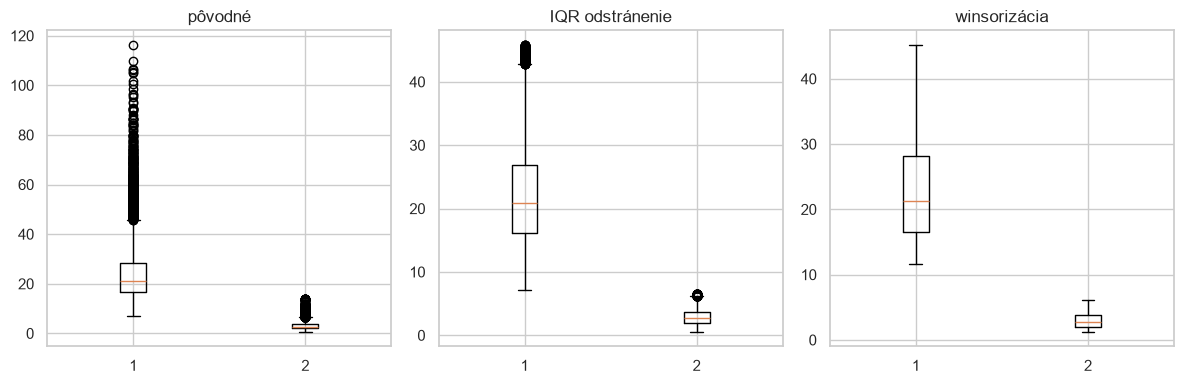

In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(12, 4))
for a, (d, t) in zip(ax, [(data_2, "pôvodné"), (data_2_removed, "IQR odstránenie"), (data_2_wins, "winsorizácia")]):
    a.boxplot([d["dp_filter"], d["rms_vibration"]], label=["dp_filter", "rms_vibration"])
    a.set_title(t)
plt.tight_layout(); plt.show()

V tomto bode `data_2` su ciste.

In [62]:
data_1.describe()

,lon,id_deport,signal_dbm,lat,id_unit
count,16000.000000,16000.000000,16000.000000,16000.000000,2000.0
mean,-7.751588,58.854125,-70.170300,40.155156,1000.5
std,0.891284,34.567290,10.006577,0.900882,577.494589
min,-9.299980,0.000000,-107.300000,38.600070,1.0
25%,-8.524577,29.000000,-77.000000,39.373440,500.75
50%,-7.758115,59.000000,-70.200000,40.163690,1000.5
75%,-6.980605,89.000000,-63.400000,40.937605,1500.25
max,-6.200070,119.000000,-40.000000,41.699910,2000.0


In [63]:
print(data_1["id_unit"].isna().sum())
print(data_1["id_unit"].value_counts().max())
print(set(data_1["id_unit"].dropna().astype(int)) - set(data_3.index))

14000
1
set()


V `data_1` má `id_unit` len 2 000 z 16 000 brán. Ide o štrukturálne chýbanie (brána nemá priradenú jednotku), nejde o chybu, preto sa nedopĺňa. Priradenie je 1:1 a bez sirôt.

In [64]:
print(data_1.duplicated().sum())
print(data_1.index.duplicated().sum())
print(data_1["mac_addr"].duplicated().sum())
print(data_1["ipv4"].duplicated().sum())

0
0
0
0


In [66]:
print(data_1["vendor"].value_counts().to_string())
print(data_1["hardware_model"].value_counts().to_string())
print(data_1["technician"].nunique(), data_1["technician"].str.strip().nunique())

vendor
Speer                            810
Tavares                          757
Pinto S.A.                       436
Nogueira                         433
Almeida                          427
Silva S/A                        426
Chapman-Guerrero                 424
Melo                             423
Holt KG                          421
Fritsch                          420
Maia                             420
Esteves                          420
Mills LLC                        420
Andrade S.A.                     417
Amorim                           415
Seidel                           414
Pacheco                          413
Patel Ltd                        411
Bailey, Schmidt and Palmer       406
Moura                            405
Abreu Monteiro e Filhos          405
Pinheiro                         401
Bell-Sosa                        400
Harrison Inc                     397
Leite                            396
Freitas Pinho S.A.               395
Freeman-Reid                   

In [67]:
for c in ["install_date", "seen_last"]:
    data_1[c] = parse_dates(data_1[c])
print(data_1[["install_date", "seen_last"]].isna().sum())
print("seen_last pred install_date:", (data_1["seen_last"] < data_1["install_date"]).sum())

install_date    0
seen_last       0
dtype: int64
seen_last pred install_date: 729


729 brán má `seen_last` pred `install_date`.

In [69]:
m = data_1.dropna(subset=["id_unit"]).copy()
m["id_unit"] = m["id_unit"].astype(int)
m = m.merge(data_3[["id_deport"]], left_on="id_unit", right_index=True, suffixes=("_gw", "_unit"))
print(len(m), (m["id_deport_gw"] != m["id_deport_unit"]).sum())

2000 0


In [70]:
bad = data_1["seen_last"] < data_1["install_date"]
print((data_1.loc[bad, "install_date"] - data_1.loc[bad, "seen_last"]).dt.days.describe())

count    729.000000
mean     117.864198
std       83.983969
min        1.000000
25%       47.000000
50%      101.000000
75%      182.000000
max      351.000000
dtype: float64


In [71]:
diff = (data_1["seen_last"] - data_1["install_date"]).dt.days
print(diff.describe())
print((diff < 0).mean(), (diff.between(-30, 0)).mean())

count    16000.000000
mean      1661.975437
std       1061.573174
min       -351.000000
25%        749.000000
50%       1649.000000
75%       2584.000000
max       3683.000000
dtype: float64
0.0455625 0.007875


729 brán (4,6 %) má `seen_last` pred `install_date` (rozdiel 1 až 351 dní). Rozdiel `seen_last` - `install_date` je široko rozptýlený (medián 1649 dní), čo nasvedčuje nezávislému zberu dátumov, nie zámene dňa a mesiaca. Hodnoty nie je možné spoľahlivo opraviť, preto sú ponechané

In [72]:
print(data_1["vendor"].nunique())
print(data_1["vendor"].value_counts().to_string())
print(data_1["hardware_model"].value_counts().to_string())

38
vendor
Speer                            810
Tavares                          757
Pinto S.A.                       436
Nogueira                         433
Almeida                          427
Silva S/A                        426
Chapman-Guerrero                 424
Melo                             423
Holt KG                          421
Fritsch                          420
Maia                             420
Esteves                          420
Mills LLC                        420
Andrade S.A.                     417
Amorim                           415
Seidel                           414
Pacheco                          413
Patel Ltd                        411
Bailey, Schmidt and Palmer       406
Moura                            405
Abreu Monteiro e Filhos          405
Pinheiro                         401
Bell-Sosa                        400
Harrison Inc                     397
Leite                            396
Freitas Pinho S.A.               395
Freeman-Reid                

In [73]:
print(sorted(data_1["vendor"].unique()))
print(sorted(data_1["hardware_model"].unique()))

['Abreu Monteiro e Filhos', 'Almeida', 'Amorim', 'Andrade S.A.', 'Bailey, Schmidt and Palmer', 'Barrett Inc', 'Bell-Sosa', 'Chapman-Guerrero', 'Clark, Moyer and Smith', 'Esteves', 'Everett, Lewis and Long', 'Freeman-Reid', 'Freitas Pinho S.A.', 'Fritsch', 'Griffin Ltd', 'Harrison Inc', 'Holt KG', 'Jackson, Navarro and Robinson', 'Koch-Moody', 'Leite', 'Maia', 'Melo', 'Mills LLC', 'Moura', 'Nogueira', 'Pacheco', 'Paiva Leite Lda.', 'Patel Ltd', 'Pinheiro', 'Pinto S.A.', 'Richards, Spears and Stokes', 'Seidel', 'Silva S/A', 'Speer', 'Säuberlich Mentzel e.G.', 'Tavares', 'Vicente S.A.', 'Zorbach']
['GWX-100', 'GWX-200', 'GWX-300', 'NODE-7', 'NODE-9']


In [74]:
print(data_1["vendor"].value_counts().to_dict())
print(data_1["hardware_model"].value_counts().to_dict())

{'Speer': 810, 'Tavares': 757, 'Pinto S.A.': 436, 'Nogueira': 433, 'Almeida': 427, 'Silva S/A': 426, 'Chapman-Guerrero': 424, 'Melo': 423, 'Holt KG': 421, 'Fritsch': 420, 'Maia': 420, 'Esteves': 420, 'Mills LLC': 420, 'Andrade S.A.': 417, 'Amorim': 415, 'Seidel': 414, 'Pacheco': 413, 'Patel Ltd': 411, 'Bailey, Schmidt and Palmer': 406, 'Moura': 405, 'Abreu Monteiro e Filhos': 405, 'Pinheiro': 401, 'Bell-Sosa': 400, 'Harrison Inc': 397, 'Leite': 396, 'Freitas Pinho S.A.': 395, 'Freeman-Reid': 392, 'Everett, Lewis and Long': 392, 'Griffin Ltd': 389, 'Richards, Spears and Stokes': 386, 'Jackson, Navarro and Robinson': 382, 'Zorbach': 372, 'Vicente S.A.': 372, 'Paiva Leite Lda.': 370, 'Barrett Inc': 363, 'Koch-Moody': 363, 'Clark, Moyer and Smith': 358, 'Säuberlich Mentzel e.G.': 349}
{'NODE-9': 3263, 'GWX-200': 3240, 'NODE-7': 3196, 'GWX-300': 3193, 'GWX-100': 3108}


In [75]:
for c in ["signal_dbm", "lat", "lon"]:
    print(c, iqr_mask(data_1[c]).sum())

signal_dbm 105
lat 0
lon 0


In [76]:
m = iqr_mask(data_1["signal_dbm"])
print(data_1.loc[m, "signal_dbm"].describe())
print((data_1.loc[m, "signal_dbm"] < -100).sum(), (data_1.loc[m, "signal_dbm"] > -45).sum())

q1, q3 = data_1["signal_dbm"].quantile([0.25, 0.75])
print(q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1))

count    105.000000
mean     -71.500000
std       30.012103
min     -107.300000
25%     -100.200000
50%      -97.500000
75%      -40.000000
max      -40.000000
Name: signal_dbm, dtype: float64
27 51
-97.4 -43.0


V `data_1` IQR metóda označila 105 hodnôt `signal_dbm` (0,66 %), `lat` a `lon` bez outlierov. 51 z nich je presne -40 dBm (horný strop merania), 54 tvorí prirodzený dolný chvost normálneho rozdelenia (-107,3 až -97,4 dBm). Hodnoty sú validné

In [77]:
d1 = data_1.reset_index()
d3 = data_3.reset_index()
m23 = data_2_wins.merge(d3, on="id_unit", how="left", validate="m:1")
print(len(data_2_wins), len(m23))
m_all = m23.merge(d1.dropna(subset=["id_unit"]), on="id_unit", how="left",
                  suffixes=("", "_gw"), validate="m:1")
print(len(m_all))
print(m_all["id_unit"].isna().sum())

13772 13772
13772
0


In [78]:
data_1.reset_index().to_csv("./data/Ciste_data/data_1_clean.csv", index=False, encoding="utf-8-sig")
data_3.reset_index().to_csv("./data/Ciste_data/data_3_clean.csv", index=False, encoding="utf-8-sig")
data_2_wins.to_csv("./data/Ciste_data/data_2_clean.csv", index=False, encoding="utf-8-sig")
m_all.to_csv("./data/Ciste_data/merged_clean.csv", index=False, encoding="utf-8-sig")

## 1.2 Report

### data_1 (gateways)

| Problém | Zistenie | Riešenie |
|---|---|---|
| Nekonzistentné názvy (`Lon`, `Vendor`, `Technician`, `macAddress`…) | Zmiešaný štýl písania | Premenované na `snake_case` (`lon`, `vendor`, `technician`, `mac_addr`…) |
| `gateway_id` je text (`GW-00001`) | Nevhodný typ | Odstránený prefix `GW-`, index prevedený na `int` |
| `seen_last`, `install_date` v 4 formátoch | `2024-04-08`, `2024/03/14`, `03 Aug 2024`, `11/07/2024, 00:00:00` | Parsovanie každého formátu zvlášť (nie `format="mixed"`); americké `mm/dd` potvrdené hodnotami typu `10/20/2024`; 0 `NaT` |
| `id_unit` je `float` a vyplnený len pri 2 000 z 16 000 brán | 14 000 `NaN`; každá jednotka má najviac jednu bránu (1:1), žiadne siroty voči `data_3` | Prevedené na `Int64`, nedopĺňa sa (brána bez jednotky nie je chýbajúce meranie) |
| `seen_last` < `install_date` | 729 brán (4,6 %), rozdiel 1 až 351 dní; rozdiel `seen_last − install_date` je výrazne rozptýlený (medián 1 649 dní), takže nejde o zámenu dňa a mesiaca | Ponechané, označené príznakom `seen_before_install` a zdokumentované |
| `signal_dbm`: 105 outlierov podľa IQR | 51 hodnôt presne −40 dBm (strop merania), 54 hodnôt od −107,3 do −97,4 dBm (prirodzený chvost) | Ponechané, sú to validné merania |

### data_2 (readings)

| Problém | Zistenie | Riešenie |
|---|---|---|
| Názvy atribútov | `currentMotor`, `oilTemperature`, `Failure`… | Premenované (`curr_motor`, `oil_temp`, `fail`…) |
| `id_unit` je text (`U00078`) | Nevhodný typ | Odstránený prvý znak, prevedené na `int` |
| `cycle_ts` v zmiešaných formátoch | Aj dátum s časom (`2023-01-02 14:07:00`) | Viacformátové parsovanie, 0 `NaT` |
| Chybné `id_unit` > 2 000 | 139 riadkov, rozsah 90 005 až 90 499 = skutočné ID + 90 000 | Odpočítaných 90 000; všetky opravené ID existujú v `data_3` |
| Plné duplicity | 208 riadkov | Odstránené (14 052 → 13 844) |
| Konfliktné duplicity (rovnaké `id_unit` a `cycle_ts`, iné hodnoty) | 72 riadkov | Zlúčené: senzory priemer, `fail` maximum, aby sa porucha nestratila (13 844 → 13 772) |
| Zástupné kódy | `oil_temp` = −999 (58×), `curr_motor` = 99 (8×), `dp_filter` = 120 (4×) | Nahradené `NaN` |
| Chýbajúce `dp_filter` (549), `rms_vibration` (518) | Pri `fail = 1` chýba 18,5 % a 16,5 %, pri `fail = 0` len 1,9 % a 2,0 % → chýbanie nie je náhodné | Doplnil mediánom podľa fail |
| `NaN` zo zástupných kódov (70 hodnôt) | `curr_motor`, `dp_filter`, `oil_temp` | Doplnené globálnym mediánom |

### data_3 (units)


| Problém | Zistenie | Riešenie |
|---|---|---|
| Názvy atribútov | `year_commission`, `serviceHours`, `serial_number`… | Premenované (`y_commission`, `serv_hours`, `serial_num`) |
| `duty_class` má 20 zápisov pre 3 triedy | `1`, `L`, `light`, `2`, `med`, `N`, `normal`, `3`, `H`, `heavy` | Zlúčené na 1, 2, 3 (804 / 686 / 510) |
| `overhaul_last` v zmiešaných formátoch | Potreba zjednotenia | Viacformátové parsovanie, 0 `NaT` |
| 100 chýbajúcich `serv_hours` | 5 % riadkov; `y_commission` korešponduje so `serv_hours` s r = −0,96 | Doplnené KNN (k = 5) len podľa `y_commission`; po doplnení sa priemer zmenil o 0,06 % |
| Strop `serv_hours` = 45 000 | 29 záznamov, všetky z roku 2012 | Ponechané (nájdený strop merania, nie chyba) |
| `overhaul_last` pred `y_commission` | 1 100 z 2 000 (55 %); Spearmanova korelácia roku overhaulu a `y_commission` je 0,037, rozdiel rokov −12 až +9 | Nie je možné opraviť (správna hodnota nie je známa); ponechané |



Pre senzory v `data_2` som porovnal dve techniky; zvolil som winsorizáciu, lebo odstránenie by zrušilo pomerne viac riadkov s poruchou než všetkých riadkov. Outliery sa hľadali až po oprave zástupných kódov (−999, 99, 120) a doplnení NaN, inak by kvantily skresľovali tieto hodnoty.

Podľa IQR je outlierov najviac v `dp_filter` (648), `rms_vibration` (516), `dis_dewp`(130), `press_reserv` (121), `oil_temp` (106) a `flow` (100); `curr_motor` nemá žiadny. Poruchy obsahujú nadpriemerne veľa extrémnych hodnôt, preto by odstránenie zrušilo práve signál, ktorý chceme modelovať. Winsorizácia najviac zmenila `dp_filter` (max 116 → 45,2) a `rms_vibration` (max 14,0 → 6,12).

 5 % / 95 % je pre `flow` a `press_reserv` (okrúhle hranice rozsahu, <1 % outlierov) agresívne a oreže 10 % hodnôt.

V `data_1` označil IQR iba `signal_dbm` (105 hodnôt, strop −40 dBm a prirodzený chvost) a ponechal som ho. `lat` a `lon` nemajú outliery. V `data_3` je strop 45 000 `serv_hours` strop merania a nepovažuje sa za outlier.
#### Spojenie tabuliek
Podmienky, ktoré integráciu umožnili: všetky `id_unit` v `data_2` aj `data_1` existujú v `data_3` (po oprave prefixu 90 000), vzťah brana–jednotka je 1:1 a `id_depot` sa v `data_1` a `data_3` zhoduje pri všetkých 2 000 pároch. 14 000 brán bez priradené jednotky sa do spojenej tabuľky nedostane a ostáva len v `data_1`.

## 1.3  Formulácia a štatistické overenie hypotéz o dátach

### Hypotéza 2: 
H0: rozdelenie `serv_hours` je rovnaké pre záznamy `fail` = 0 aj `fail` = 1.

H1: pri `fail` = 1 sú serv_hours vyššie (jednostranný test).

Hladina významnosti: `α` = 0,05.

In [79]:
units = (data_2_wins.groupby("id_unit")["fail"].max()
         .rename("any_fail").to_frame()
         .join(data_3[["serv_hours", "y_commission"]]))
print(units["any_fail"].value_counts())
print(units.groupby("any_fail")["serv_hours"].describe().round(1))

any_fail
1    1024
0     975
Name: count, dtype: int64
           count     mean     std     min     25%      50%      75%      max
any_fail                                                                    
0          975.0  12610.3  7546.0  1303.0  7462.4  10744.8  15913.7  45000.0
1         1024.0  16463.9  9700.9  2078.5  9400.5  14151.5  20618.0  45000.0


In [80]:
g0 = units.loc[units.any_fail == 0, "serv_hours"]
g1 = units.loc[units.any_fail == 1, "serv_hours"]

print(stats.shapiro(g0.sample(min(len(g0), 5000), random_state=0)))
print(stats.shapiro(g1.sample(min(len(g1), 5000), random_state=0)))
print(stats.levene(g0, g1))

ShapiroResult(statistic=np.float64(0.8710179317197817), pvalue=np.float64(1.3134362451151339e-27))
ShapiroResult(statistic=np.float64(0.8987050206870586), pvalue=np.float64(1.9204490752837797e-25))
LeveneResult(statistic=np.float64(42.5370188291892), pvalue=np.float64(8.762351073257836e-11))


Normalita aj rozdelenie dat sú porušené, použili sme Mann-Whitney U test

In [86]:
u, p = stats.mannwhitneyu(g1, g0, alternative="greater")
print("Mann-Whitney U:", u, "p =", p)

Mann-Whitney U: 624894.0 p = 9.783886875793858e-23


In [83]:
print(stats.ttest_ind(g1, g0, equal_var=False, alternative="greater"))

TtestResult(statistic=np.float64(9.93981219927324), pvalue=np.float64(4.890520857558139e-23), df=np.float64(1921.3630638152276))


In [90]:
n1, n0 = len(g1), len(g0)
rbc = 2 * u / (n1 * n0) - 1
print("rank-biserial r:", round(rbc, 3), "| P(serv_hours poruchy > bez poruchy):", round(u / (n1*n0), 3))
rng = np.random.default_rng(0)
diffs = [np.median(rng.choice(g1, n1)) - np.median(rng.choice(g0, n0)) for _ in range(5000)]
print("rozdiel mediánov:", np.median(g1) - np.median(g0), "CI:", np.percentile(diffs, [2.5, 97.5]).round(0))

rank-biserial r: 0.252 | P(serv_hours poruchy > bez poruchy): 0.626
rozdiel mediánov: 3406.7000000000007 CI: [2593. 4185.]


## Vysledok
H0 zamietame (U = 624 894, p < 0,001). Jednotky s poruchou majú vyššie `serv_hours` (medián 14 152 h oproti 10 745 h); rozdiel mediánov je 3 407 h (95 % CI 2 593 až 4 185 h). Veľkosť účinku je malá až stredná (rank-biserial r = 0,252): v 62,6 % náhodných dvojíc má jednotka s poruchou viac hodín.

In [95]:
from statsmodels.stats.power import TTestIndPower
pw = TTestIndPower()
n0, n1 = len(g0), len(g1)

sp = np.sqrt(((n0-1)*g0.var() + (n1-1)*g1.var()) / (n0+n1-2))
d = (g1.mean() - g0.mean()) / sp
print("Cohen d:", round(d, 3))

print("power:", pw.power(effect_size=d, nobs1=n0, ratio=n1/n0, alpha=0.05, alternative="larger"))

mde = pw.solve_power(nobs1=n0, ratio=n1/n0, alpha=0.05, power=0.8, alternative="larger")
print("minimálne d pri 0.8:", round(mde, 3))

print("n na skupinu pre d=0.2:", int(np.ceil(pw.solve_power(effect_size=0.2, alpha=0.05, power=0.8, alternative="larger"))))

from scipy import stats
rng = np.random.default_rng(0)
hits = sum(stats.mannwhitneyu(rng.choice(g1, n1), rng.choice(g0, n0), alternative="greater").pvalue < 0.05
           for _ in range(1000))
print("simulovaná sila:", hits / 1000)

Cohen d: 0.442
power: 0.9999999999999999
minimálne d pri 0.8: 0.111
n na skupinu pre d=0.2: 310
simulovaná sila: 1.0


## Sila testu
Štatistická sila bola posúdená pri α = 0,05 a konvenčnom prahu 0,8 pre 975 jednotiek bez poruchy a 1 024 s poruchou. Pri pozorovanom účinku (Cohenovo d = 0,442) vychádza sila ≈ 1,00; simulácia priamo pre Mann-Whitneyho test ju potvrdila (sila = 1,00). Dosiahnutá sila je teda výrazne nad prahom 0,8.

Pri tejto veľkosti vzorky by test so silou 0,8 zachytil už účinok d ≈ 0,11, ktorý je výrazne menší než pozorovaný, takže vzorka je dostatočná na spoľahlivé zachytenie aj slabšieho účinku. Pre d = 0,2 by na dosiahnutie sily 0,8 stačilo 310 jednotiek na skupinu, čo je približne tretina dostupného počtu.

## Podiel prace 
50 - Horshchar Yevhen / 50 - 